# 1. Introduction and Problem Formulation

## 1.1 Introduction and Motivation

Diabetes is a major global public-health concern. The World Health Organization reported that approximately 830 million people were living with diabetes in 2022, with prevalence increasing more rapidly in low- and middle-income countries than in high-income countries [1]. Prediabetes is also important because people may have elevated blood glucose without knowing it. In the United States, the Centers for Disease Control and Prevention reports that approximately eight in ten adults with prediabetes are unaware of their condition [2].

This project is motivated by the possibility of using technology to improve health awareness and encourage people to seek professional screening. My interest in this problem is partly personal, because someone in my family lives with diabetes. This made me think about how a simple mobile application might help people become more aware of their health, especially when they are busy with everyday responsibilities.

The long-term vision is an accessible application that uses health-related information to provide an initial indication that a person may benefit from a medical checkup. The application would not diagnose diabetes or replace healthcare professionals. Instead, it would encourage users to seek appropriate screening when necessary.

To investigate this idea, the project applies traditional machine-learning algorithms and deep neural networks to a public diabetes health-indicators dataset. The experiments focus on classifying three categories: no diabetes, prediabetes, and diabetes. Particular attention is given to prediabetes because it is the smallest class and has been difficult for the models to identify.

## 1.2 Problem Statement

People may remain unaware of prediabetes or diabetes, particularly when symptoms are absent or have not yet been recognized. Accessible risk-awareness tools could potentially encourage people to seek screening earlier. However, developing a reliable tool requires evidence that health indicators can support useful predictions and that the model performs adequately across different population groups.

The technical problem addressed in this project is the classification of diabetes-related status using demographic, lifestyle, and health indicators. The dataset contains a substantial imbalance between its three classes, especially the prediabetes class. This creates a challenge because a model can achieve high overall accuracy while failing to identify people in the minority class.

The project therefore investigates whether traditional machine learning and deep learning can classify these three categories effectively, and whether techniques such as class weighting, focal loss, oversampling, and prediction-threshold adjustment improve minority-class detection without producing excessive false positives.

The current dataset represents survey-reported health status rather than laboratory-confirmed diagnosis or future disease onset. Consequently, this project is an exploratory classification study and an initial step toward the broader idea of a non-diagnostic health-awareness application. Developing a reliable risk-screening application would require additional research and validation using appropriate clinical or longitudinal data.

## 1.3 Project Aim

To compare traditional machine-learning algorithms and deep neural networks for classifying survey-reported diabetes status using health indicators, with particular emphasis on improving prediabetes detection and investigating the potential of data-driven tools to encourage professional health screening.

## 1.4 Project Objectives

1. Explore and preprocess the diabetes health-indicators dataset, examining its structure, feature characteristics, duplicate records, and class distribution.
2. Develop and compare traditional machine-learning models and deep neural networks using a reproducible training and evaluation process.
3. Investigate methods for handling class imbalance, including class weighting, focal loss, random oversampling, and prediction-threshold adjustment.
4. Evaluate the models using accuracy, macro F1-score, class-specific precision and recall, ROC-AUC, average precision, confusion matrices, and learning curves.
5. Select the strongest candidate models using validation performance and evaluate them on an untouched test set.
6. Identify limitations and propose improvements needed before such a model could support a practical health-awareness application.

## 1.5 Research Questions

This study addresses the following questions:

1. How do traditional machine-learning models compare with deep neural networks when classifying no diabetes, prediabetes, and diabetes from health indicators?
2. How does class imbalance affect model performance, particularly the ability to identify prediabetes?
3. Which evaluated approaches provide the most appropriate balance between precision, recall, and macro F1-score?
4. How well do the selected models generalize to an unseen test set?
5. What additional data, validation, and safeguards would be required before this approach could support a health-awareness application?

## 1.6 Dataset Selection and Justification

This project uses the Diabetes Health Indicators dataset published by Alex Teboul on Kaggle, derived from the 2015 Behavioral Risk Factor Surveillance System (BRFSS) survey [3], [4]. The original selected CSV contains 253,680 records and 22 columns: 21 predictor features and one target variable, `Diabetes_012`.

The predictors include age, body mass index (BMI), high blood pressure, high cholesterol, physical activity, general health, smoking, and other demographic and lifestyle indicators. The target represents three diabetes-related categories: no diabetes (0), prediabetes (1), and diabetes (2).

The dataset was selected because it is publicly accessible, large enough for systematic experimentation, contains a variety of health indicators, and supports a meaningful comparison between traditional machine learning and deep learning. Its three-class target also allows the study to investigate the specific challenge of recognizing prediabetes rather than treating all diabetes-related conditions as one category.

However, the labels are based on reported survey status rather than laboratory-confirmed diagnosis. The dataset also comes from a US population and reflects information collected in 2015. Its findings cannot automatically be generalized to Rwanda or other countries. The strong class imbalance further makes it necessary to examine class-specific metrics instead of relying on accuracy alone [4], [5].


## 2. Data Loading and Initial Inspection

In this section, we load the original dataset and examine its basic structure before making any changes. This helps us understand the number of observations and features, identify the target variable, and establish a baseline for later preprocessing decisions.

We preserve the original dataset so that any cleaning or transformation can be performed on a separate copy. This allows us to compare our preprocessing choices and keep the analysis reproducible.

In [6]:
# Import the required libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
import wandb
import sklearn
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize
from sklearn.base import clone
from sklearn.model_selection import learning_curve
import time
import wandb
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from imblearn.over_sampling import RandomOverSampler
from collections import Counter
from catboost import CatBoostClassifier
import joblib
from pathlib import Path
from datetime import datetime
from sklearn.utils.class_weight import compute_class_weight
import json





In [7]:
# loading the original csv data
data = pd.read_csv("data/diabetes_012_health_indicators_BRFSS2015.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


In [8]:
data.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [9]:
# checking the dimension of our dataset
print("Number of rows and columns:", data.shape)


Number of rows and columns: (253680, 22)


Interpretation: Each row represents an observation, and each column represents a recorded variable. I inspected 253,680 rows and 22 columns based on our earlier results.

In [10]:
# Identifying the predictors and the target
target = "Diabetes_012"

features = [
    column for column in data.columns
    if column != target
]

print("Target variable:", target)
print("Number of predictor features:", len(features))
print("Predictor names:", features)

Target variable: Diabetes_012
Number of predictor features: 21
Predictor names: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


Interpretation: Diabetes_012 is what we want the model to predict. The other 21 columns are the inputs used to make that prediction.

In [11]:
# Inspecting the datatype
data.dtypes

Diabetes_012            float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object

Interpretation: The output tells us how pandas stores each column. I will later classify the variables according to their actual meaning, rather than treating all float64 columns as continuous features.

In [12]:
data.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


In [13]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

## 3. Data Quality Assessment

Before preparing the dataset for machine learning, we need to assess its quality and identify any issues that could affect model training and evaluation. This includes checking for missing values, examining the target class distribution, investigating duplicate records, and verifying that feature values are consistent with their expected meanings.

The results of these checks will guide our preprocessing decisions. Rather than automatically removing or modifying data, we will investigate potential issues and justify any changes using evidence. This approach helps preserve useful information and makes our analysis reproducible.

In [14]:
# Check for missing values in each column
missing_values = data.isnull().sum()

print("Missing values per column:")
print(missing_values.to_string())

print("\nTotal missing values:", missing_values.sum())

Missing values per column:
Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0

Total missing values: 0


Interpretation: The missing-value check found no missing entries in any of the 22 columns. Therefore, we do not currently need to apply imputation methods, such as replacing missing values with the mean, median, or mode.

However, this result only confirms that pandas did not detect standard missing values. It does not guarantee that every entry is valid, because some datasets may use numeric codes to represent specific responses or special conditions. I will investigate the possible values of each feature in a later step before finalizing our preprocessing decisions.

## 3.2 Target Class Distribution
The target variable, `Diabetes_012`, contains the categories our model will learn to predict. Examining the number and percentage of observations in each category helps us understand the balance of the classification problem.

This is particularly important because a model trained on an imbalanced dataset may perform well on the most common class while performing poorly on less common classes. We will use the results to guide our choice of evaluation metrics and determine whether class-imbalance strategies should be investigated.

In [15]:
# Count observations in each target class
target_counts = data["Diabetes_012"].value_counts().sort_index()

# Calculate the percentage of each class
target_percentages = (
    data["Diabetes_012"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

# Combine counts and percentages into one table
target_distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages.round(2)
})

print(target_distribution)

               Count  Percentage (%)
Diabetes_012                        
0.0           213703           84.24
1.0             4631            1.83
2.0            35346           13.93


The target classes are imbalanced. Class 0 represents 84.24% of the data, Class 1 represents 1.83%, and Class 2 represents 13.93%. Class 1 has very few samples compared with the other classes, which may make it harder for the model to predict correctly. Therefore, I will use evaluation metrics that show how well the model performs on each class, not just its overall accuracy.

### 3.3 Duplicate Records
Duplicate records can affect model training and evaluation. I will count exact duplicate rows to understand how often identical records appear before deciding whether removing them is appropriate.

In [16]:
# Count exact duplicate rows
duplicate_count = data.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)
print("Percentage of dataset:", round(
    duplicate_count / len(data) * 100, 2
), "%")

Number of exact duplicate rows: 23899
Percentage of dataset: 9.42 %


The dataset contains 23,899 exact duplicate rows, representing 9.42% of all records. However, identical rows may belong to different survey respondents with the same answers. Therefore, I will investigate the duplicates before deciding whether removing them is appropriate.

### 3.4 Investigating Duplicate Patterns

Exact duplicate rows have identical feature values and target labels. However, different rows may share the same feature values but have different target labels. We will check for these conflicting patterns before deciding how to handle duplicates.

In [17]:
# Count each target class within every predictor pattern
pattern_labels = (
    data.groupby(features + ["Diabetes_012"], dropna=False)
    .size()
    .unstack(fill_value=0)
)

# Keep patterns that have more than one target label
conflicts = pattern_labels[
    (pattern_labels > 0).sum(axis=1) > 1
]

# Select all records belonging to those conflicting patterns
indexed_data = data.set_index(features)
conflicting_rows = indexed_data[
    indexed_data.index.isin(conflicts.index)
].reset_index()

# Count records from each target class
conflict_class_counts = (
    conflicting_rows["Diabetes_012"]
    .value_counts()
    .sort_index()
)

conflict_class_percentages = (
    conflicting_rows["Diabetes_012"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

conflict_summary = pd.DataFrame({
    "Count": conflict_class_counts,
    "Percentage (%)": conflict_class_percentages.round(2)
})

print("Conflicting predictor patterns:", len(conflicts))
print("Rows in conflicting patterns:", len(conflicting_rows))
print("\nTarget class distribution:")
print(conflict_summary)

Conflicting predictor patterns: 1834
Rows in conflicting patterns: 6120

Target class distribution:
              Count  Percentage (%)
Diabetes_012                       
0.0            4096           66.93
1.0             338            5.52
2.0            1686           27.55


## Investigating the Number of Conflicting Classes

We will examine whether each conflicting predictor pattern is associated with two or three target classes. This helps us understand the extent of disagreement in the recorded labels before deciding how to handle these patterns.

In [18]:
# Count the number of target classes in each conflicting pattern
classes_per_pattern = (conflicts > 0).sum(axis=1)

# Summarize patterns by the number of classes
pattern_summary = classes_per_pattern.value_counts().sort_index()

print("Number of conflicting patterns by class count:")
print(pattern_summary.to_string())

Number of conflicting patterns by class count:
2    1795
3      39


Out of 1,834 conflicting predictor patterns, 1,795 are associated with two target classes, while 39 are associated with all three classes. This shows that most conflicting patterns involve two different labels. However, these differences do not necessarily mean the records are incorrect, so I will not automatically remove them.

In [19]:
# Count patterns containing each combination of target classes
class_presence = conflicts > 0

class_combinations = (
    class_presence.groupby(
        list(class_presence.columns),
        dropna=False
    )
    .size()
    .sort_values(ascending=False)
)

print("Conflicting patterns by target-class combination:")
print(class_combinations.to_string())

Conflicting patterns by target-class combination:
0.0    1.0    2.0  
True   False  True     1497
       True   False     268
              True       39
False  True   True       30


Most conflicting patterns (1,497) occur between class 0 and class 2. Another 268 patterns involve classes 0 and 1, while 30 involve classes 1 and 2. Only 39 patterns contain all three classes. These findings show that conflicting labels mainly occur between the no-diabetes and diabetes categories. However, we cannot determine the cause of these differences from the available features alone, so we will preserve the original records until we have justified a preprocessing strategy.

### 3.5 Unique Values and Feature Coding

In this section, I examine the values recorded in each column to understand how the features are represented. This helps us identify unexpected values and distinguish between binary variables, categorical variables, ordinal variables, and numerical measurements.

I will compare the observed values with the dataset documentation before deciding whether any corrections or transformations are needed.

We first count the number of distinct values in each column. This provides an overview of how each variable is represented and helps us identify columns that need closer inspection.


In [20]:
# Count distinct values in each column
unique_counts = data.nunique()

print("Number of unique values per column:")
print(unique_counts.to_string())

Number of unique values per column:
Diabetes_012             3
HighBP                   2
HighChol                 2
CholCheck                2
BMI                     84
Smoker                   2
Stroke                   2
HeartDiseaseorAttack     2
PhysActivity             2
Fruits                   2
Veggies                  2
HvyAlcoholConsump        2
AnyHealthcare            2
NoDocbcCost              2
GenHlth                  5
MentHlth                31
PhysHlth                31
DiffWalk                 2
Sex                      2
Age                     13
Education                6
Income                   8


Next, I will inspect the actual values recorded in each feature. This helps us identify unexpected codes and understand which variables need to be checked against the dataset codebook.

In [21]:
# Display the distinct values in each column
for column in data.columns:
    values = sorted(data[column].dropna().unique())
    print(f"{column}: {values}")

Diabetes_012: [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
HighBP: [np.float64(0.0), np.float64(1.0)]
HighChol: [np.float64(0.0), np.float64(1.0)]
CholCheck: [np.float64(0.0), np.float64(1.0)]
BMI: [np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(44.0), np.float64(45.0), np.float64(46.0), np.float64(47.0), np.float64(48.0), np.float64(49.0), np.float64(50.0), np.float64(51.0), np.float64(52.0), np.float64(53.0), np.float64(54.0), np.float64(55.0), np

Smoker: [np.float64(0.0), np.float64(1.0)]
Stroke: [np.float64(0.0), np.float64(1.0)]
HeartDiseaseorAttack: [np.float64(0.0), np.float64(1.0)]
PhysActivity: [np.float64(0.0), np.float64(1.0)]
Fruits: [np.float64(0.0), np.float64(1.0)]
Veggies: [np.float64(0.0), np.float64(1.0)]
HvyAlcoholConsump: [np.float64(0.0), np.float64(1.0)]
AnyHealthcare: [np.float64(0.0), np.float64(1.0)]
NoDocbcCost: [np.float64(0.0), np.float64(1.0)]
GenHlth: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
MentHlth: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.fl

* Most features contain the expected number of values for binary or ordinal variables. However, BMI contains some unusually high values, including 95, 96, and 98. We will examine their frequencies and distribution before deciding whether they require any special treatment. We will also verify feature coding using the dataset documentation.

### Investigating BMI Values

BMI is a numerical feature, so we will examine its distribution and the frequency of unusually high values. This will help us decide whether further investigation is needed without removing valid observations prematurely.

In [22]:
# Summarize the BMI distribution
print("BMI summary:")
print(
    data["BMI"].describe(
        percentiles=[0.95, 0.99, 0.995, 0.999]
    )
)

# Count BMI values of 50 or higher
high_bmi = data.loc[data["BMI"] >= 50, "BMI"]

print("\nNumber of records with BMI >= 50:", len(high_bmi))
print("\nFrequency of BMI values >= 50:")
print(high_bmi.value_counts().sort_index().to_string())

BMI summary:
count    253680.000000
mean         28.382364
std           6.608694
min          12.000000
95%          40.000000
99%          50.000000
99.5%        55.000000
99.9%        81.000000
max          98.000000
Name: BMI, dtype: float64

Number of records with BMI >= 50: 2547

Frequency of BMI values >= 50:
BMI
50.0    372
51.0    253
52.0    215
53.0    237
54.0    113
55.0    169
56.0    109
57.0     86
58.0     71
59.0     54
60.0     63
61.0     35
62.0     43
63.0     34
64.0     24
65.0     19
66.0     13
67.0     15
68.0     14
69.0      9
70.0     15
71.0     49
72.0     14
73.0     47
74.0     16
75.0     52
76.0      3
77.0     55
78.0      1
79.0     66
80.0      2
81.0     49
82.0     37
83.0      2
84.0     44
85.0      1
86.0      1
87.0     61
88.0      2
89.0     28
90.0      1
91.0      1
92.0     32
95.0     12
96.0      1
98.0      7


The BMI values range from 12 to 98, with a mean of 28.38. The 99th percentile is 50, and 2,547 records have BMI values of 50 or higher. These values are uncommon and deserve further investigation, but they are not automatically errors. I will check their validity and distribution before deciding whether any treatment is necessary.

### Visual Inspection of BMI

I will use a boxplot to examine the BMI distribution and identify values that may be statistical outliers. These values will be investigated rather than automatically removed, because an unusual measurement may still be valid.

/tmp/ipykernel_225075/1063060397.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(data["BMI"], vert=False)


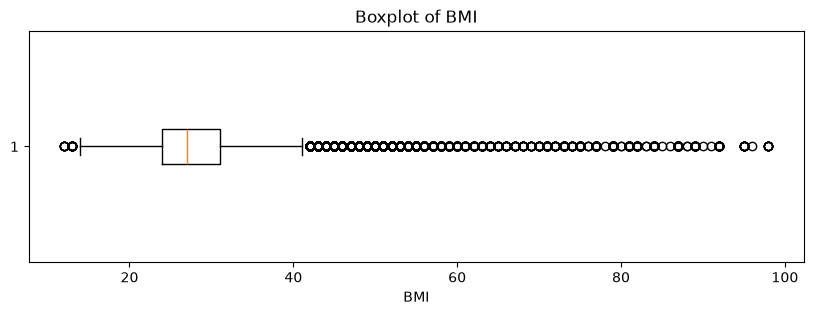

In [23]:
plt.figure(figsize=(10, 3))
plt.boxplot(data["BMI"], vert=False)
plt.title("Boxplot of BMI")
plt.xlabel("BMI")
plt.show()

The boxplot shows a right-skewed BMI distribution, with many potential outliers above the upper whisker and a few below the lower whisker. These values may represent genuine observations rather than errors. Therefore, I will retain the original BMI values for now and investigate them further before deciding whether any treatment is necessary.

### Codebook Verification

I will compare the observed feature values with the documented meanings of the survey variables. This helps us distinguish valid categories and measurements from special codes that may require attention. I will consider the processing applied to the Kaggle dataset before deciding whether any values need to be changed.

In [24]:
# Group features by their likely meanings
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost",
    "DiffWalk", "Sex"
]

ordinal_features = [
    "GenHlth", "Age", "Education", "Income"
]

day_count_features = ["MentHlth", "PhysHlth"]
numerical_features = ["BMI"]

print("Binary features:", len(binary_features))
print("Ordinal features:", len(ordinal_features))
print("Day-count features:", len(day_count_features))
print("Numerical features:", len(numerical_features))

Binary features: 14
Ordinal features: 4
Day-count features: 2
Numerical features: 1


The feature categories were initially identified by examining the observed values in the dataset. The meanings and coding of the variables will be verified using the official CDC 2015 BRFSS Codebook, while considering that the Kaggle dataset is a processed version of the original survey data.

I will examine the documented meanings of selected features and compare them with the values observed in our dataset. This helps us understand what each variable represents and identify any coding issues before preprocessing.

In [25]:
features_to_check = [
    "Age",
    "Education",
    "Income",
    "GenHlth",
    "MentHlth",
    "PhysHlth"
]

for feature in features_to_check:
    print(f"{feature}: {sorted(data[feature].dropna().unique())}")

Age: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0)]
Education: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0)]
Income: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0)]
GenHlth: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
MentHlth: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), 

Feature	Observed values	Meaning
Age	1–13	Age categories, not actual ages in years
Education	1–6	Ordered education levels
Income	1–8	Ordered income categories
GenHlth	1–5	Self-reported general health, from excellent to poor
MentHlth	0–30	Number of days in the past 30 days when mental health was not good
PhysHlth	0–30	Number of days in the past 30 days when physical health was not good

### Data Quality Assessment Summary

The initial assessment found no standard missing values, but the target classes are imbalanced, with the prediabetes class being particularly underrepresented. The dataset also contains exact duplicate records and predictor patterns associated with different target labels. BMI contains some unusually high values that require careful interpretation rather than automatic removal. These findings will guide our preprocessing and evaluation decisions while helping us preserve valid information in the original dataset.

### 3.8 Exploratory Data Analysis (EDA)
Exploratory Data Analysis (EDA) helps us understand the distribution of the target variable, the relationships between features, and patterns that may be relevant to diabetes prediction. I will use visualizations to identify important trends and guide our preprocessing and model development decisions.

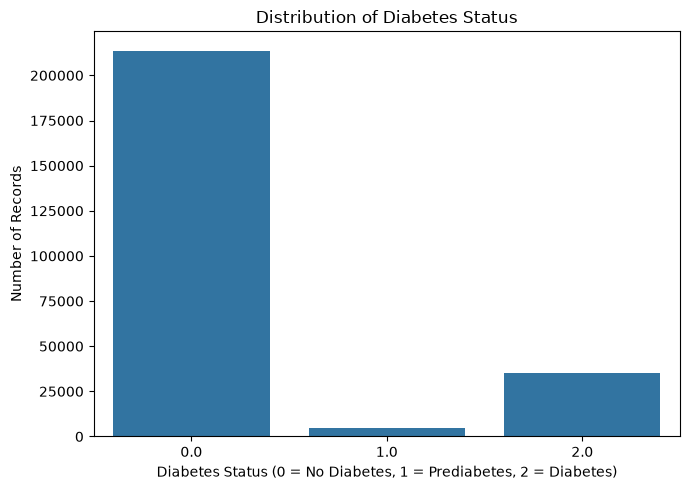

In [26]:
# plot for target class distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=data, x="Diabetes_012")

plt.title("Distribution of Diabetes Status")
plt.xlabel("Diabetes Status (0 = No Diabetes, 1 = Prediabetes, 2 = Diabetes)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

The target distribution shows a strong class imbalance. Most records belong to individuals without diabetes (class 0), followed by individuals with diabetes (class 2). The prediabetes class (class 1) has very few records in comparison. This imbalance may cause a model to favor the majority class and perform poorly when identifying prediabetes. Therefore, I will evaluate performance for each class rather than relying only on overall accuracy.

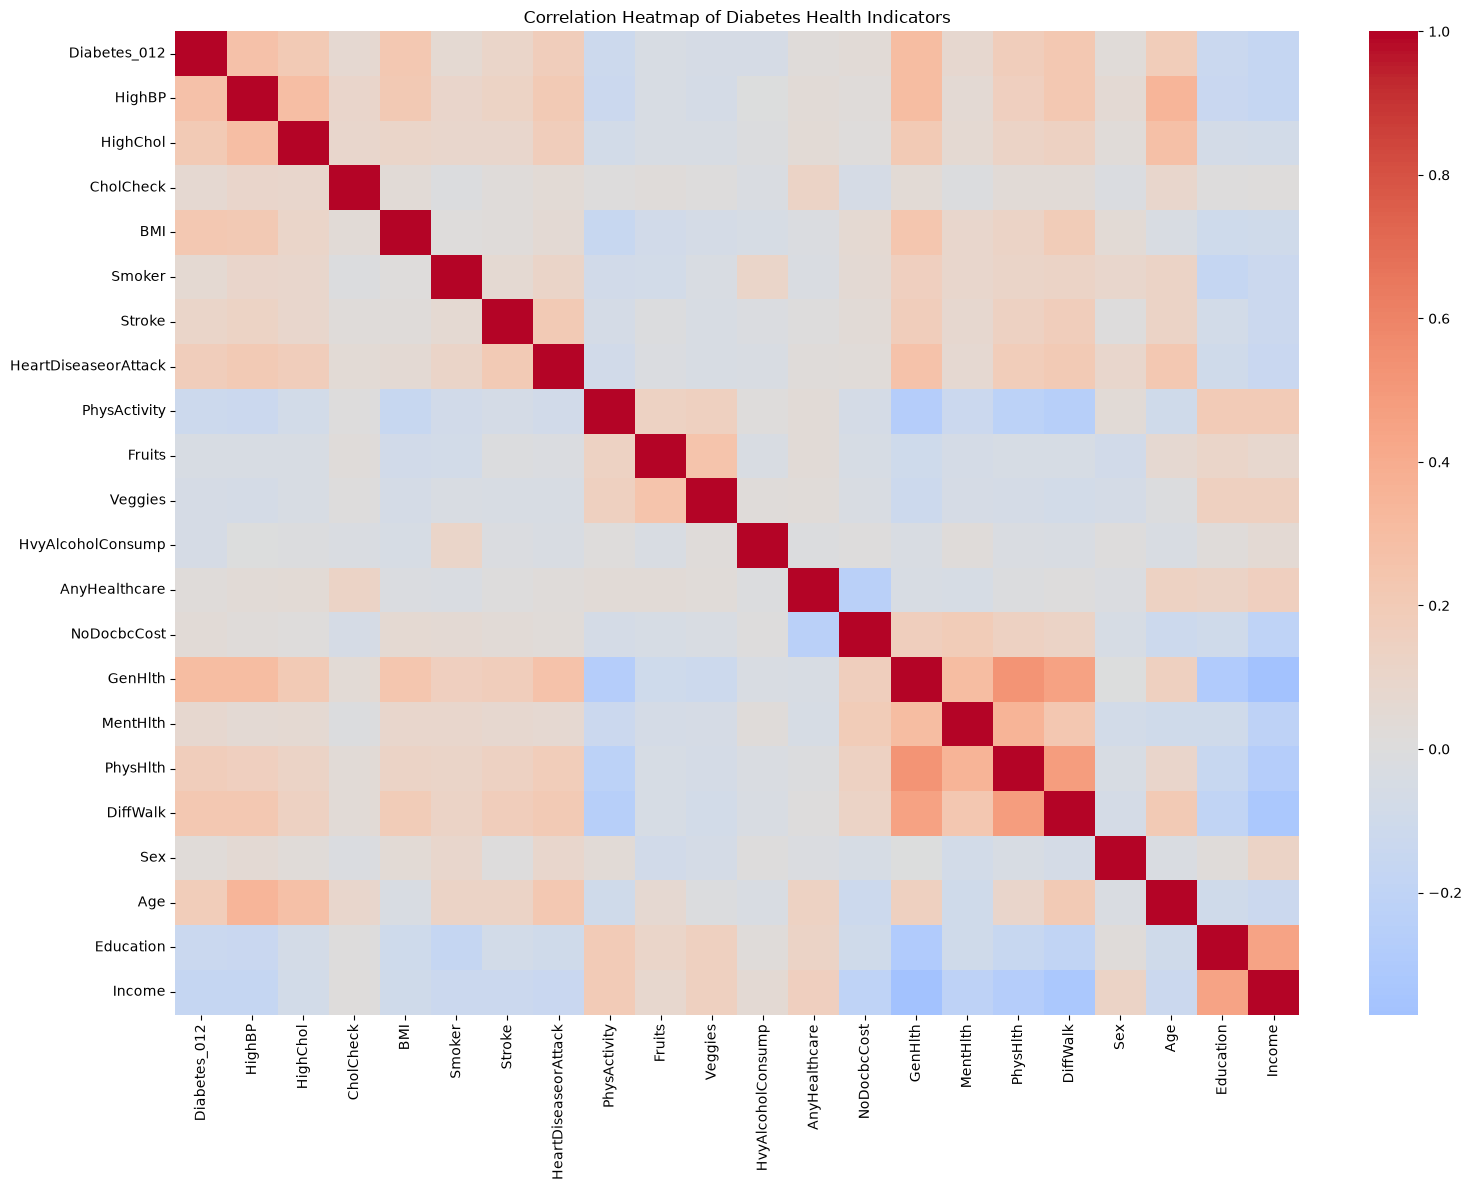

In [27]:
# plot for feature correlation heatmap
correlation_matrix = data.corr(numeric_only=True)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Diabetes Health Indicators")
plt.tight_layout()
plt.show()

The correlation heatmap suggests that diabetes status has positive associations with several health-related features, including high blood pressure, high cholesterol, BMI, age, and general health. Some predictors are also correlated with one another. However, most relationships appear weak to moderate. Since the target contains three categories and several predictors are encoded categorical variables, Pearson correlation provides only an initial view of these relationships and does not establish causation.

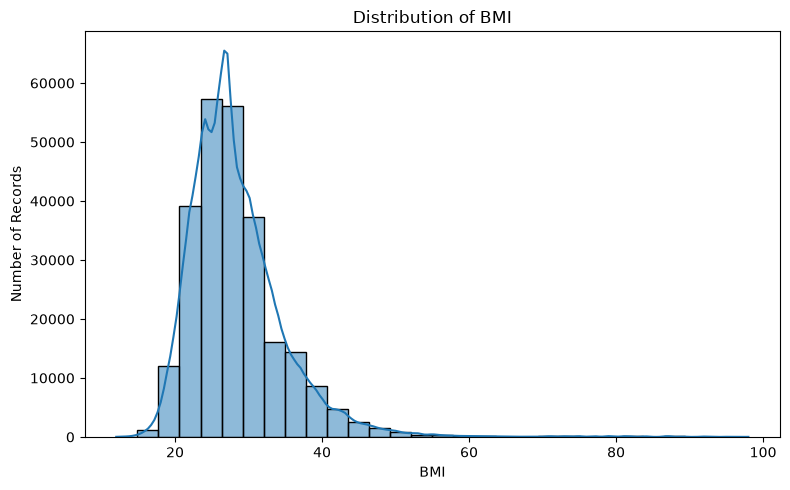

In [28]:
# plot for BMI distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=data, x="BMI", bins=30, kde=True)

plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

The BMI distribution is right-skewed, meaning that most records have lower BMI values while a smaller number have much higher values. Most observations fall approximately between 20 and 40, with the highest concentration around the mid-to-upper 20s. A small number of records have BMI values above 50. These values should be investigated carefully, but they should not automatically be removed because high values may be genuine.

We'll compare diabetes status across high blood pressure and high cholesterol. Because the target has three classes, a grouped percentage chart can help us compare the class composition more fairly than raw counts alone.

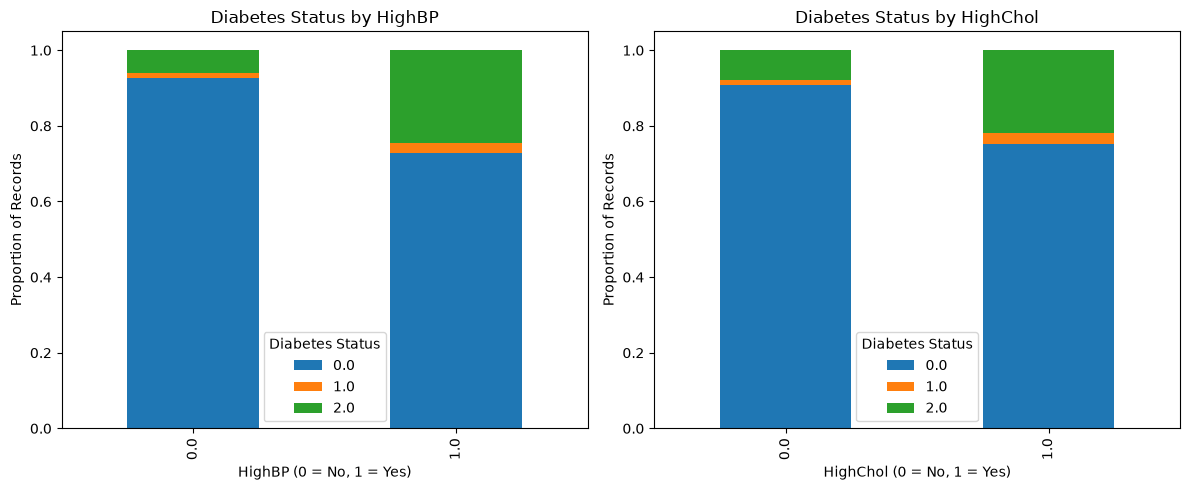

In [29]:
# plot for diabetes status by selected features
selected_features = ["HighBP", "HighChol"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, feature in zip(axes, selected_features):
    proportions = pd.crosstab(
        data[feature],
        data["Diabetes_012"],
        normalize="index"
    )

    proportions.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(f"Diabetes Status by {feature}")
    ax.set_xlabel(f"{feature} (0 = No, 1 = Yes)")
    ax.set_ylabel("Proportion of Records")
    ax.legend(title="Diabetes Status")

plt.tight_layout()
plt.show()

The charts show that the proportion of individuals in the diabetes class (class 2) is higher among those reporting high blood pressure or high cholesterol than among those reporting neither condition. Conversely, the proportion without diabetes (class 0) is lower in these groups. This suggests that high blood pressure and high cholesterol may be useful predictors of diabetes status. However, these visual patterns show associations and do not prove that either condition causes diabetes.

The EDA revealed three important findings: the target variable is strongly imbalanced, BMI is right-skewed with a small number of unusually high values, and diabetes status shows associations with several health-related features. The analysis also suggests that high blood pressure and high cholesterol may help distinguish diabetes status. These findings will guide our preprocessing, model selection, and evaluation strategy. Further analysis will be needed to determine how well the models identify each class.

# Section 4: Data Preprocessing and Feature Preparation
## 4.1 Separate Features and Target
In this section, we prepare the dataset for machine learning. We will first separate the input features from the target variable and split the original data into training, validation, and test sets. We will preserve the original dataset while investigating duplicates, conflicting predictor patterns, and unusual values before deciding how to handle them.

In [30]:
# Separate input features and target variable

X = data.drop(columns=["Diabetes_012"])
y = data["Diabetes_012"]

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Feature dataset shape: (253680, 21)
Target dataset shape: (253680,)


The dataset contains 253,680 records, 21 input features, and one target variable, Diabetes_012. The target is separated from the input features, so the model can learn to predict diabetes status.

## 4.2 Split the Data
I'll use a 70% training, 15% validation, and 15% test split. Stratification helps preserve the proportions of the three target classes in each set.

In [31]:
# First, separate 15% for the test set
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Then take 15% of the original dataset for validation
# 15 / 85 gives the required validation fraction of the remaining data
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (177576, 21) (177576,)
Validation set: (38052, 21) (38052,)
Test set: (38052, 21) (38052,)


The training set contains 177,576 records (70%), while the validation and test sets each contain 38,052 records (15%). This gives us separate data for model training, model selection, and final evaluation.

In [32]:
split_distribution = pd.DataFrame({
    "Original (%)": y.value_counts(normalize=True).sort_index() * 100,
    "Training (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Validation (%)": y_val.value_counts(normalize=True).sort_index() * 100,
    "Test (%)": y_test.value_counts(normalize=True).sort_index() * 100
})

split_distribution.index.name = "Diabetes Status"

print(split_distribution.round(2))

                 Original (%)  Training (%)  Validation (%)  Test (%)
Diabetes Status                                                      
0.0                     84.24         84.24           84.24     84.24
1.0                      1.83          1.83            1.83      1.83
2.0                     13.93         13.93           13.93     13.93


Stratification maintained the original class proportions in all three sets: 84.24% for class 0, 1.83% for class 1, and 13.93% for class 2. However, the prediabetes class remains underrepresented, so we will need to pay special attention to its evaluation metrics.

In [33]:
# Check exact duplicate rows within each split

print("Training exact duplicates:", X_train.join(y_train).duplicated().sum())
print("Validation exact duplicates:", X_val.join(y_val).duplicated().sum())
print("Test exact duplicates:", X_test.join(y_test).duplicated().sum())

Training exact duplicates: 14164
Validation exact duplicates: 1189
Test exact duplicates: 1270


In [34]:
train_records = X_train.copy()
train_records["Diabetes_012"] = y_train

val_records = X_val.copy()
val_records["Diabetes_012"] = y_val

test_records = X_test.copy()
test_records["Diabetes_012"] = y_test

train_keys = set(map(tuple, train_records.to_numpy()))
val_keys = set(map(tuple, val_records.to_numpy()))
test_keys = set(map(tuple, test_records.to_numpy()))

print("Training-validation overlaps:", len(train_keys & val_keys))
print("Training-test overlaps:", len(train_keys & test_keys))
print("Validation-test overlaps:", len(val_keys & test_keys))

Training-validation overlaps: 3473
Training-test overlaps: 3466
Validation-test overlaps: 1316


In [35]:
# Give identical predictor combinations the same group ID
groups = X.groupby(
    X.columns.tolist(),
    dropna=False,
    sort=False
).ngroup()

# First: set aside 15% for testing
splitter_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_idx, test_idx = next(
    splitter_test.split(X, y, groups=groups)
)

# Second: set aside approximately 15% of the full dataset for validation
X_train_val = X.iloc[train_val_idx]
y_train_val = y.iloc[train_val_idx]
groups_train_val = groups.iloc[train_val_idx]

splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=42
)

train_idx, val_idx = next(
    splitter_val.split(
        X_train_val,
        y_train_val,
        groups=groups_train_val
    )
)

# Create the new splits
X_train = X_train_val.iloc[train_idx]
y_train = y_train_val.iloc[train_idx]

X_val = X_train_val.iloc[val_idx]
y_val = y_train_val.iloc[val_idx]

X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (177251, 21) (177251,)
Validation: (38203, 21) (38203,)
Test: (38226, 21) (38226,)


In [36]:
split_distribution = pd.DataFrame({
    "Training (%)": y_train.value_counts(normalize=True) * 100,
    "Validation (%)": y_val.value_counts(normalize=True) * 100,
    "Test (%)": y_test.value_counts(normalize=True) * 100
}).sort_index()

print(split_distribution.round(2))

              Training (%)  Validation (%)  Test (%)
Diabetes_012                                        
0.0                  84.21           84.08     84.55
1.0                   1.82            1.88      1.79
2.0                  13.97           14.04     13.66


In [37]:
train_groups = set(groups.loc[X_train.index])
val_groups = set(groups.loc[X_val.index])
test_groups = set(groups.loc[X_test.index])

print("Train-validation overlap:", len(train_groups & val_groups))
print("Train-test overlap:", len(train_groups & test_groups))
print("Validation-test overlap:", len(val_groups & test_groups))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


Interpratation: To reduce potential data leakage, the dataset was split using groups based on identical predictor combinations. The resulting training, validation, and test sets contained no overlapping predictor groups. The class proportions remained similar across the three sets, although small differences occurred because entire groups were kept together. This approach provides a more cautious evaluation of how well the models generalize to previously unseen predictor combinations.

## Section 4.3 Investigating and Handling Duplicate Records
Before deciding whether to remove duplicate records, I will examine their frequency and determine whether identical records have the same target label. Repeated survey responses do not necessarily represent data errors, so I will preserve the original dataset and evaluate the effect of deduplication separately.

In [38]:
# Count exact duplicate records without modifying the original data

total_rows = len(data)
duplicate_rows = data.duplicated().sum()
unique_rows = len(data.drop_duplicates())

print("Original number of rows:", total_rows)
print("Exact duplicate rows:", duplicate_rows)
print("Unique complete records:", unique_rows)
print("Percentage of duplicate rows:", round(duplicate_rows / total_rows * 100, 2), "%")

Original number of rows: 253680
Exact duplicate rows: 23899
Unique complete records: 229781
Percentage of duplicate rows: 9.42 %


In [39]:
# Create a separate version with exact duplicate rows removed

data_deduplicated = data.drop_duplicates().copy()

print("Original dataset shape:", data.shape)
print("Deduplicated dataset shape:", data_deduplicated.shape)

print(
    "Duplicates remaining:",
    data_deduplicated.duplicated().sum()
)

Original dataset shape: (253680, 22)
Deduplicated dataset shape: (229781, 22)
Duplicates remaining: 0


In [40]:
comparison = pd.DataFrame({
    "Original (%)": (
        data["Diabetes_012"].value_counts(normalize=True) * 100
    ),
    "Deduplicated (%)": (
        data_deduplicated["Diabetes_012"].value_counts(normalize=True) * 100
    )
}).sort_index()

comparison.index.name = "Diabetes Status"

print(comparison.round(2))

                 Original (%)  Deduplicated (%)
Diabetes Status                                
0.0                     84.24             82.71
1.0                      1.83              2.01
2.0                     13.93             15.27


The dataset contains 23,899 exact duplicate rows, representing 9.42% of the original records. Removing these rows reduces the dataset to 229,781 records and changes the target distribution: the proportion of class 0 decreases, while the proportions of classes 1 and 2 increase. Since identical survey responses do not necessarily represent data errors, the original dataset will be retained for the primary analysis, while the deduplicated dataset will be evaluated separately as a sensitivity experiment.

In [41]:
# Count target labels for identical predictor combinations

pattern_label_counts = data.groupby(
    X.columns.tolist(),
    dropna=False
)["Diabetes_012"].nunique()

conflicting_patterns = pattern_label_counts[
    pattern_label_counts > 1
]

print("Conflicting predictor patterns:", len(conflicting_patterns))
print(
    "Number of records belonging to conflicting patterns:",
    data.groupby(X.columns.tolist(), dropna=False)
        .filter(lambda group: group["Diabetes_012"].nunique() > 1)
        .shape[0]
)

Conflicting predictor patterns: 1834
Number of records belonging to conflicting patterns: 6120


The analysis identified 1,834 predictor patterns associated with multiple target labels, involving 6,120 records. This indicates that identical observed predictor values do not always correspond to the same diabetes status. These records may reflect differences not captured by the available features or limitations in the survey data. I will retain them in the primary dataset rather than remove them automatically, since doing so could introduce bias and reduce the diversity of the target classes.

In [42]:
# Examine the highest BMI values and their frequencies

bmi_counts = (
    data["BMI"]
    .value_counts()
    .sort_index()
)

print("BMI values of 50 or higher:")
print(bmi_counts[bmi_counts.index >= 50])

print("\nNumber of records with BMI >= 50:",
      (data["BMI"] >= 50).sum())

print("Number of records with BMI < 15:",
      (data["BMI"] < 15).sum())

BMI values of 50 or higher:
BMI
50.0    372
51.0    253
52.0    215
53.0    237
54.0    113
55.0    169
56.0    109
57.0     86
58.0     71
59.0     54
60.0     63
61.0     35
62.0     43
63.0     34
64.0     24
65.0     19
66.0     13
67.0     15
68.0     14
69.0      9
70.0     15
71.0     49
72.0     14
73.0     47
74.0     16
75.0     52
76.0      3
77.0     55
78.0      1
79.0     66
80.0      2
81.0     49
82.0     37
83.0      2
84.0     44
85.0      1
86.0      1
87.0     61
88.0      2
89.0     28
90.0      1
91.0      1
92.0     32
95.0     12
96.0      1
98.0      7
Name: count, dtype: int64

Number of records with BMI >= 50: 2547
Number of records with BMI < 15: 68


**BMI Outlier Investigation**

The BMI analysis identified 2,547 records with BMI values of 50 or higher and 68 records with BMI values below 15. These values are at the extremes of the observed distribution, but they are not necessarily data-entry errors. Therefore, I will retain them in the primary dataset rather than removing valid observations without sufficient evidence.

In [43]:
# Separate the input features from the target variable
X = data.drop(columns=["Diabetes_012"])
y = data["Diabetes_012"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Validation target:", y_val.shape)
print("Test target:", y_test.shape)

Training features: (177251, 21)
Validation features: (38203, 21)
Test features: (38226, 21)

Training target: (177251,)
Validation target: (38203,)
Test target: (38226,)


Our dataset has different types of features, so we should not automatically treat every column the same way.
- Binary features: Already encoded as 0 and 1.
- Ordinal features: GenHlth, Age, Education, and Income have ordered categories.
- Day-count features: MentHlth and PhysHlth.
- BMI: A numerical feature.
For a fair comparison, we'll use a ColumnTransformer to apply scaling where appropriate. Scaling is particularly useful for logistic regression and neural networks. Tree-based models such as Random Forest generally do not require it

In [44]:
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost",
    "DiffWalk", "Sex"
]

ordinal_features = ["GenHlth", "Age", "Education", "Income"]

numeric_features = ["BMI", "MentHlth", "PhysHlth"]

# Scale numeric and ordinal features; leave binary features unchanged
preprocessor = ColumnTransformer(
    transformers=[
        ("binary", "passthrough", binary_features),
        ("ordinal", StandardScaler(), ordinal_features),
        ("numeric", StandardScaler(), numeric_features)
    ],
    remainder="drop"
)

In [45]:
# Learn preprocessing parameters from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same parameters to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed validation data:", X_val_processed.shape)
print("Processed test data:", X_test_processed.shape)

Processed training data: (177251, 21)
Processed validation data: (38203, 21)
Processed test data: (38226, 21)


 Here I scaled the ordinal features while preserving their order, but this treats the gaps between their coded values as approximately equal. That is a practical modeling choice, not a claim that every category has an equal real-world difference.

In [46]:
# Check the processed data for missing or infinite values

for name, X_processed in [
    ("Training", X_train_processed),
    ("Validation", X_val_processed),
    ("Test", X_test_processed)
]:
    print(
        f"{name}: "
        f"NaN values = {np.isnan(X_processed).sum()}, "
        f"Infinite values = {np.isinf(X_processed).sum()}"
    )

Training: NaN values = 0, Infinite values = 0
Validation: NaN values = 0, Infinite values = 0
Test: NaN values = 0, Infinite values = 0


**Preprocessing Results and Data Leakage Prevention**

The preprocessing pipeline was successfully applied to the training, validation, and test sets. The dataset contains 21 input features, and the number of rows in each feature set matches its corresponding target labels. StandardScaler was fitted only on the training data and then applied to the validation and test data using the same learned parameters. Binary features were left unchanged. All three processed datasets contained zero missing and infinite values. This approach helps prevent data leakage and ensures a fairer evaluation of model performance.


In [47]:
# Project configuration
WANDB_PROJECT = "diabetes-health-indicators"
WANDB_MODE = "online"
RANDOM_STATE = 42

# Local folders for results and saved models
RESULTS_DIR = Path("results")
MODELS_DIR = Path("saved_models")

RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

CLASS_NAMES = ["No diabetes", "Prediabetes", "Diabetes"]
CLASS_LABELS = [0, 1, 2]

# Reproducibility
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("W&B:", wandb.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("W&B mode:", WANDB_MODE)
print("Models will be saved in:", MODELS_DIR.resolve())


W&B: 0.30.0
Scikit-learn: 1.9.0
TensorFlow: 2.21.0
GPU devices: []
W&B mode: online
Models will be saved in: /home/janviere-munezero/Documents/ML/Introduction to ML/diabetes-risk-prediction/saved_models


E0000 00:00:1792501678.382617  225075 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [48]:
WANDB_MODE = "offline"

In [49]:
CLASS_NAMES = ["No diabetes", "Prediabetes", "Diabetes"]
CLASS_LABELS = [0, 1, 2]


def evaluate_and_log(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    experiment_name,
    config,
    mode="online",
    log_learning_curve=False
):
    """Train, evaluate, and log one Scikit-Learn experiment."""

    run = wandb.init(
        project=WANDB_PROJECT,
        name=experiment_name,
        mode=mode,
        config=config,
        reinit="finish_previous"
    )

    try:
        start_time = time.time()
        if "sample_weight" in config:
            model.fit(
                X_train,
                y_train,
                sample_weight=config["sample_weight"]
            )
        else:
            model.fit(X_train, y_train)
        training_seconds = time.time() - start_time

        predictions = model.predict(X_val)

        # Core metrics
        metrics = {
            "validation/accuracy": accuracy_score(y_val, predictions),
            "validation/macro_f1": f1_score(
                y_val, predictions, average="macro", zero_division=0
            ),
            "validation/weighted_f1": f1_score(
                y_val, predictions, average="weighted", zero_division=0
            ),
            "validation/macro_precision": precision_score(
                y_val, predictions, average="macro", zero_division=0
            ),
            "validation/macro_recall": recall_score(
                y_val, predictions, average="macro", zero_division=0
            ),
            # "training/seconds": training_seconds
        }

        report = classification_report(
            y_val,
            predictions,
            labels=CLASS_LABELS,
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0
        )

        for class_id, class_name in zip(CLASS_LABELS, CLASS_NAMES):
            metrics[f"validation/{class_name}/precision"] = (
                report[class_name]["precision"]
            )
            metrics[f"validation/{class_name}/recall"] = (
                report[class_name]["recall"]
            )
            metrics[f"validation/{class_name}/f1"] = (
                report[class_name]["f1-score"]
            )

        # Confusion matrix
        cm = confusion_matrix(y_val, predictions, labels=CLASS_LABELS)
        fig, ax = plt.subplots(figsize=(6, 5))
        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=CLASS_NAMES
        ).plot(ax=ax, values_format="d", cmap="Blues", colorbar=False)
        ax.set_title(f"Confusion Matrix — {experiment_name}")
        fig.tight_layout()
        wandb.log({
            **metrics,
            "validation/confusion_matrix": wandb.Image(fig)
        })
        plt.close(fig)

        # ROC-AUC and precision-recall curves require class probabilities.
        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(X_val)
            class_order = list(model.classes_)

            # Align probability columns to class labels 0, 1, 2.
            probabilities = probabilities[
                :, [class_order.index(c) for c in CLASS_LABELS]
            ]
            y_binary = label_binarize(y_val, classes=CLASS_LABELS)



            # One-vs-rest ROC curves
            fig, ax = plt.subplots(figsize=(7, 5))
            for i, name in enumerate(CLASS_NAMES):
                fpr, tpr, _ = roc_curve(y_binary[:, i], probabilities[:, i])
                auc_i = roc_auc_score(y_binary[:, i], probabilities[:, i])
                ax.plot(fpr, tpr, label=f"{name} (AUC={auc_i:.3f})")

            ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
            ax.set(
                xlabel="False Positive Rate",
                ylabel="True Positive Rate",
                title=f"One-vs-Rest ROC — {experiment_name}"
            )
            ax.legend()
            fig.tight_layout()
            wandb.log({"validation/roc_curves": wandb.Image(fig)})
            plt.close(fig)

            # One-vs-rest precision-recall curves
            fig, ax = plt.subplots(figsize=(7, 5))
            for i, name in enumerate(CLASS_NAMES):
                precision, recall, _ = precision_recall_curve(
                    y_binary[:, i], probabilities[:, i]
                )
                ap = average_precision_score(
                    y_binary[:, i], probabilities[:, i]
                )
                metrics[f"validation/{name}/average_precision"] = ap
                ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

            ax.set(
                xlabel="Recall",
                ylabel="Precision",
                title=f"Precision–Recall Curves — {experiment_name}"
            )
            ax.legend()
            fig.tight_layout()
            wandb.log({"validation/precision_recall_curves": wandb.Image(fig)})
            plt.close(fig)

        # Optional learning curve for traditional ML.
        # This can be computationally expensive, so use it selectively.
        if log_learning_curve:
            sizes, train_scores, val_scores = learning_curve(
                clone(model),
                X_train,
                y_train,
                train_sizes=np.linspace(0.1, 1.0, 5),
                cv=3,
                scoring="f1_macro",
                n_jobs=-1
            )

            fig, ax = plt.subplots(figsize=(7, 5))
            ax.plot(
                sizes, train_scores.mean(axis=1),
                marker="o", label="Training macro F1"
            )
            ax.plot(
                sizes, val_scores.mean(axis=1),
                marker="o", label="Cross-validation macro F1"
            )
            ax.set(
                xlabel="Number of training samples",
                ylabel="Macro F1",
                title=f"Learning Curve — {experiment_name}"
            )
            ax.legend()
            fig.tight_layout()
            wandb.log({"learning_curve": wandb.Image(fig)})
            plt.close(fig)

        # Log metrics after adding AUC and average precision values.
        wandb.log(metrics)

        print(classification_report(
            y_val,
            predictions,
            labels=CLASS_LABELS,
            target_names=CLASS_NAMES,
            zero_division=0
        ))
        print("Logged metrics:", metrics)

        return model, metrics

    finally:
        wandb.finish()

### Experiment 1: Logistic Regression Baseline
I am using Logistic Regression as my first model because it is a simple, interpretable classification algorithm. It estimates the probability of each class using a linear combination of the input features. This provides a useful starting point before testing more complex models.

I set max_iter=1000 to give the algorithm enough iterations to converge during training and used RANDOM_STATE to support reproducibility.

In [50]:
logistic_baseline = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

model_1, metrics_1 = evaluate_and_log(
    model=logistic_baseline,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp01-logistic-regression-baseline",
    config={
        "model": "Logistic Regression",
        "max_iter": 1000,
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)


              precision    recall  f1-score   support

 No diabetes       0.86      0.98      0.91     32121
 Prediabetes       0.00      0.00      0.00       719
    Diabetes       0.53      0.18      0.27      5363

    accuracy                           0.85     38203
   macro avg       0.46      0.38      0.39     38203
weighted avg       0.80      0.85      0.81     38203

Logged metrics: {'validation/accuracy': 0.8453524592309505, 'validation/macro_f1': 0.3936333122896094, 'validation/weighted_f1': 0.806563191620433, 'validation/macro_precision': 0.46284053892943006, 'validation/macro_recall': 0.3845341108706153, 'validation/No diabetes/precision': 0.8611584327086882, 'validation/No diabetes/recall': 0.9757168207714579, 'validation/No diabetes/f1': 0.9148653579508137, 'validation/Prediabetes/precision': 0.0, 'validation/Prediabetes/recall': 0.0, 'validation/Prediabetes/f1': 0.0, 'validation/Diabetes/precision': 0.527363184079602, 'validation/Diabetes/recall': 0.17788551184038784,

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


Interpretation: The baseline Logistic Regression model achieved 84.54% validation accuracy and a macro F1-score of 0.394. However, its performance varied considerably across the three classes. It performed well in identifying individuals without diabetes, achieving a recall of 97.57%, but failed to correctly identify any individuals in the Prediabetes class. Its recall for the Diabetes class was also low at 17.79%.

These results show that accuracy alone is insufficient for evaluating this imbalanced multiclass classification problem. The model's poor performance on minority classes motivates testing class-weighted learning and alternative algorithms in subsequent experiments.

### Experiment 2: Logistic Regression with Balanced Class Weights
In Experiment 1, I trained a baseline Logistic Regression model without class weighting. Since the dataset is highly imbalanced, the model may favored the majority class, which represents people reporting no diabetes.

In this experiment, I set class_weight="balanced". This automatically assigns greater importance to minority-class examples and lower importance to majority-class examples during training. I keep max_iter=1000 and the same random state so that the main change is the class-weighting strategy.

In [51]:
logistic_weighted = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

model_2, metrics_2 = evaluate_and_log(
    model=logistic_weighted,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp02-logistic-regression-balanced",
    config={
        "model": "Logistic Regression",
        "class_weight": "balanced",
        "max_iter": 1000,
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)

              precision    recall  f1-score   support

 No diabetes       0.95      0.67      0.78     32121
 Prediabetes       0.03      0.29      0.05       719
    Diabetes       0.36      0.59      0.45      5363

    accuracy                           0.65     38203
   macro avg       0.45      0.51      0.43     38203
weighted avg       0.85      0.65      0.72     38203

Logged metrics: {'validation/accuracy': 0.6474622411852472, 'validation/macro_f1': 0.42805175102835885, 'validation/weighted_f1': 0.7215052373392782, 'validation/macro_precision': 0.4466244184936016, 'validation/macro_recall': 0.514973646287834, 'validation/No diabetes/precision': 0.9491804006929946, 'validation/No diabetes/recall': 0.6652034494567417, 'validation/No diabetes/f1': 0.7822155513252307, 'validation/Prediabetes/precision': 0.03015873015873016, 'validation/Prediabetes/recall': 0.2906815020862309, 'validation/Prediabetes/f1': 0.054647666361615894, 'validation/Diabetes/precision': 0.36053412462908013, 

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


In [52]:

comparison = pd.DataFrame([
    {"Experiment": "Logistic Regression Baseline", **metrics_1},
    {"Experiment": "Logistic Regression Balanced", **metrics_2}
])

display(
    comparison[
        [
            "Experiment",
            "validation/accuracy",
            "validation/macro_f1",
            "validation/Prediabetes/precision",
            "validation/Prediabetes/recall",
            "validation/Diabetes/recall"
        ]
    ].round(4)
)


,Experiment,validation/accuracy,validation/macro_f1,validation/Prediabetes/precision,validation/Prediabetes/recall,validation/Diabetes/recall
0,Logistic Regression Baseline,0.8454,0.3936,0.0000,0.0000,0.1779
1,Logistic Regression Balanced,0.6475,0.4281,0.0302,0.2907,0.5890


### Experiment 3: Balanced Random Forest

In this experiment, I introduce Random Forest, which combines multiple decision trees to learn complex, nonlinear relationships between health indicators. I use 200 trees, `min_samples_leaf=2`, and balanced class weights to improve minority-class detection. This experiment tests whether a tree-based ensemble performs better than Logistic Regression, particularly in identifying prediabetes and diabetes.

In [53]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_3, metrics_3 = evaluate_and_log(
    model=random_forest,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp03-random-forest-balanced",
    config={
        "model": "Random Forest",
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 2,
        "class_weight": "balanced",
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)


              precision    recall  f1-score   support

 No diabetes       0.93      0.79      0.85     32121
 Prediabetes       0.03      0.01      0.02       719
    Diabetes       0.35      0.68      0.46      5363

    accuracy                           0.76     38203
   macro avg       0.43      0.49      0.44     38203
weighted avg       0.83      0.76      0.78     38203

Logged metrics: {'validation/accuracy': 0.7583435855822841, 'validation/macro_f1': 0.44279719201340656, 'validation/weighted_f1': 0.7810145163913259, 'validation/macro_precision': 0.433586173935083, 'validation/macro_recall': 0.4934890991676135, 'validation/No diabetes/precision': 0.9269399707174232, 'validation/No diabetes/recall': 0.7883938856199993, 'validation/No diabetes/f1': 0.8520718022913477, 'validation/Prediabetes/precision': 0.02849002849002849, 'validation/Prediabetes/recall': 0.013908205841446454, 'validation/Prediabetes/f1': 0.018691588785046728, 'validation/Diabetes/precision': 0.34532852259779717

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


The class-weighted Random Forest achieved 75.83% validation accuracy and a macro F1-score of 0.4428, the highest macro F1-score among the three experiments so far. It also achieved the highest Diabetes recall of the three models at 0.6782, with a Diabetes F1-score of 0.4576. However, its Prediabetes recall was only 0.0139, substantially lower than that of the class-weighted Logistic Regression model. This indicates that the Random Forest performed better overall according to macro F1 and identified more Diabetes cases, but it struggled to identify Prediabetes cases. Therefore, it cannot yet be considered the best model for every class.

### Experiment 4: Tuned Random Forest

In this experiment, I adjust the Random Forest parameters to control model complexity and improve generalization. I set `max_depth=20` to limit tree depth and `min_samples_leaf=5` to require more samples in each leaf, while keeping 200 trees and balanced class weights. I compare these changes with Experiment 3 to determine whether simpler trees reduce overfitting and improve minority-class classification.

In [54]:
random_forest_tuned = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_4, metrics_4 = evaluate_and_log(
    model=random_forest_tuned,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp04-random-forest-tuned",
    config={
        "model": "Random Forest",
        "n_estimators": 200,
        "max_depth": 20,
        "min_samples_leaf": 5,
        "class_weight": "balanced",
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)

              precision    recall  f1-score   support

 No diabetes       0.94      0.73      0.82     32121
 Prediabetes       0.02      0.04      0.03       719
    Diabetes       0.32      0.73      0.45      5363

    accuracy                           0.71     38203
   macro avg       0.43      0.50      0.43     38203
weighted avg       0.84      0.71      0.75     38203

Logged metrics: {'validation/accuracy': 0.7146035651650394, 'validation/macro_f1': 0.43265388357995943, 'validation/weighted_f1': 0.7527344101157795, 'validation/macro_precision': 0.42890105210328017, 'validation/macro_recall': 0.4995161772316629, 'validation/No diabetes/precision': 0.9397110315128587, 'validation/No diabetes/recall': 0.7269076305220884, 'validation/No diabetes/f1': 0.8197233534615924, 'validation/Prediabetes/precision': 0.023634881825590873, 'validation/Prediabetes/recall': 0.04033379694019471, 'validation/Prediabetes/f1': 0.029804727646454265, 'validation/Diabetes/precision': 0.323357242971390

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


In [55]:

comparison = pd.DataFrame([
    {"Experiment": "Logistic Regression Baseline", **metrics_1},
    {"Experiment": "Logistic Regression Balanced", **metrics_2},
    {"Experiment": "Random Forest Balanced", **metrics_3},
    {"Experiment": "Random Forest Tuned", **metrics_4}

])

display(
    comparison[
        [
    "Experiment",
    "validation/accuracy",
    "validation/macro_f1",
    "validation/weighted_f1",
    "validation/No diabetes/precision",
    "validation/No diabetes/recall",
    "validation/No diabetes/f1",
    "validation/Prediabetes/precision",
    "validation/Prediabetes/recall",
    "validation/Prediabetes/f1",
    "validation/Diabetes/precision",
    "validation/Diabetes/recall",
    "validation/Diabetes/f1"
        ]
    ].round(4)
)


,Experiment,validation/accuracy,validation/macro_f1,validation/weighted_f1,validation/No diabetes/precision,validation/No diabetes/recall,validation/No diabetes/f1,validation/Prediabetes/precision,validation/Prediabetes/recall,validation/Prediabetes/f1,validation/Diabetes/precision,validation/Diabetes/recall,validation/Diabetes/f1
0,Logistic Regression Baseline,0.8454,0.3936,0.8066,0.8612,0.9757,0.9149,0.0000,0.0000,0.0000,0.5274,0.1779,0.2660
1,Logistic Regression Balanced,0.6475,0.4281,0.7215,0.9492,0.6652,0.7822,0.0302,0.2907,0.0546,0.3605,0.5890,0.4473
2,Random Forest Balanced,0.7583,0.4428,0.7810,0.9269,0.7884,0.8521,0.0285,0.0139,0.0187,0.3453,0.6782,0.4576
3,Random Forest Tuned,0.7146,0.4327,0.7527,0.9397,0.7269,0.8197,0.0236,0.0403,0.0298,0.3234,0.7313,0.4484


The tuned Random Forest achieved 71.46% validation accuracy and a macro F1-score of 0.4327. Compared with the original class-weighted Random Forest, its macro F1-score decreased from 0.4428 to 0.4327, indicating that limiting tree depth and increasing the minimum number of samples per leaf did not improve overall class-balanced performance.

The model achieved a Diabetes recall of 0.7313, higher than the 0.6782 obtained by the original Random Forest. However, its Diabetes precision decreased from 0.3453 to 0.3234, and its F1-score decreased slightly from 0.4576 to 0.4484. This suggests that the tuned model identified more Diabetes cases but also produced more false-positive predictions.

Prediabetes performance remained poor. Its recall increased slightly from 0.0139 to 0.0403, but its F1-score was only 0.0298 and its precision was 0.0236. The model also had lower recall for the No diabetes class than the original Random Forest.

Overall, tuning the Random Forest increased Diabetes recall but did not improve macro F1 or the F1-scores for the individual classes. The original class-weighted Random Forest therefore remains the stronger of these two configurations according to macro F1. Further experiments will investigate other traditional machine learning algorithms before selecting the best model.

### Experiment 5: Gradient Boosting Baseline

This experiment uses Gradient Boosting, which builds decision trees sequentially, with each tree correcting errors made by previous trees. We use 100 estimators, a learning rate of 0.1, and a maximum depth of 3. The model is evaluated on the validation set to measure its predictive performance.

In [56]:
gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)

model_5, metrics_5 = evaluate_and_log(
    model=gradient_boosting,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp05-gradient-boosting-baseline",
    config={
        "model": "Gradient Boosting",
        "n_estimators": 100,
        "learning_rate": 0.1,
        "max_depth": 3,
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)

              precision    recall  f1-score   support

 No diabetes       0.86      0.98      0.92     32121
 Prediabetes       0.00      0.00      0.00       719
    Diabetes       0.56      0.20      0.29      5363

    accuracy                           0.85     38203
   macro avg       0.47      0.39      0.40     38203
weighted avg       0.80      0.85      0.81     38203

Logged metrics: {'validation/accuracy': 0.8482841661649608, 'validation/macro_f1': 0.402105817094244, 'validation/weighted_f1': 0.8111687045227459, 'validation/macro_precision': 0.47356171083943227, 'validation/macro_recall': 0.39071873616429736, 'validation/No diabetes/precision': 0.8634210816169182, 'validation/No diabetes/recall': 0.9761838049873914, 'validation/No diabetes/f1': 0.9163464207957683, 'validation/Prediabetes/precision': 0.0, 'validation/Prediabetes/recall': 0.0, 'validation/Prediabetes/f1': 0.0, 'validation/Diabetes/precision': 0.5572640509013785, 'validation/Diabetes/recall': 0.1959724035055006

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


Interpratation: The Gradient Boosting baseline achieved 84.83% validation accuracy and a macro F1-score of 0.4021. Although it achieved the highest accuracy among the five experiments so far, its performance was uneven across the three classes.

The model performed well on the No diabetes class, achieving a recall of 97.62% and an F1-score of 0.9163. However, it failed to identify any Prediabetes cases, resulting in a precision, recall, and F1-score of zero for that class. Its Diabetes recall was also low at 19.60%, meaning that it missed most individuals belonging to the Diabetes class.

Compared with the baseline Logistic Regression model, Gradient Boosting achieved slightly higher accuracy (84.83% compared with 84.54%) and a higher macro F1-score (0.4021 compared with 0.3936). It also achieved better Diabetes precision and F1-score. Nevertheless, neither model identified any Prediabetes cases.

Overall, the results demonstrate that Gradient Boosting performs well on the majority class but struggles to identify the minority classes. Its high accuracy is partly influenced by the large proportion of No diabetes records. Therefore, accuracy alone is insufficient for selecting the best model. Further experiments should investigate approaches that improve minority-class performance.

### Experiment 6: Balanced Gradient Boosting

This experiment addresses class imbalance by assigning higher weights to minority-class records. I use the same Gradient Boosting parameters as Experiment 5 to evaluate whether balanced sample weights improve the model's predictive performance.

In [57]:
# Give greater weight to records from minority classes
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

gradient_boosting_balanced = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)

model_6, metrics_6 = evaluate_and_log(
    model=gradient_boosting_balanced,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="exp06-gradient-boosting-balanced",
    config={
        "model": "Gradient Boosting",
        "n_estimators": 100,
        "learning_rate": 0.1,
        "max_depth": 3,
        "class_weighting": "balanced sample weights",
        "sample_weight": sample_weights,
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)

wandb: WARNING Serializing object of type ndarray that is 1418120 bytes


              precision    recall  f1-score   support

 No diabetes       0.96      0.63      0.76     32121
 Prediabetes       0.03      0.34      0.06       719
    Diabetes       0.36      0.62      0.45      5363

    accuracy                           0.62     38203
   macro avg       0.45      0.53      0.42     38203
weighted avg       0.85      0.62      0.70     38203

Logged metrics: {'validation/accuracy': 0.6231971311153575, 'validation/macro_f1': 0.4230194169162629, 'validation/weighted_f1': 0.7035302857655762, 'validation/macro_precision': 0.44791326849916385, 'validation/macro_recall': 0.5291776728576961, 'validation/No diabetes/precision': 0.956470421604268, 'validation/No diabetes/recall': 0.630708882039787, 'validation/No diabetes/f1': 0.7601590934674121, 'validation/Prediabetes/precision': 0.03169469598965071, 'validation/Prediabetes/recall': 0.34075104311543813, 'validation/Prediabetes/f1': 0.0579950289975145, 'validation/Diabetes/precision': 0.35557468790357294, 'v

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


In [58]:
comparison = pd.DataFrame([
    {"Experiment": "Logistic Regression Baseline", **metrics_1},
    {"Experiment": "Logistic Regression Balanced", **metrics_2},
    {"Experiment": "Random Forest Balanced", **metrics_3},
    {"Experiment": "Random Forest Tuned", **metrics_4},
    {"Experiment": "Gradient Boosting Baseline", **metrics_5},
    {"Experiment": "Gradient Boosting Balanced", **metrics_6}



])

display(
    comparison[
        [
    "Experiment",
    "validation/accuracy",
    "validation/macro_f1",
    "validation/weighted_f1",
    "validation/No diabetes/precision",
    "validation/No diabetes/recall",
    "validation/No diabetes/f1",
    "validation/Prediabetes/precision",
    "validation/Prediabetes/recall",
    "validation/Prediabetes/f1",
    "validation/Diabetes/precision",
    "validation/Diabetes/recall",
    "validation/Diabetes/f1"
        ]
    ].round(4)
)


,Experiment,validation/accuracy,validation/macro_f1,validation/weighted_f1,validation/No diabetes/precision,validation/No diabetes/recall,validation/No diabetes/f1,validation/Prediabetes/precision,validation/Prediabetes/recall,validation/Prediabetes/f1,validation/Diabetes/precision,validation/Diabetes/recall,validation/Diabetes/f1
0,Logistic Regression Baseline,0.8454,0.3936,0.8066,0.8612,0.9757,0.9149,0.0000,0.0000,0.0000,0.5274,0.1779,0.2660
1,Logistic Regression Balanced,0.6475,0.4281,0.7215,0.9492,0.6652,0.7822,0.0302,0.2907,0.0546,0.3605,0.5890,0.4473
2,Random Forest Balanced,0.7583,0.4428,0.7810,0.9269,0.7884,0.8521,0.0285,0.0139,0.0187,0.3453,0.6782,0.4576
3,Random Forest Tuned,0.7146,0.4327,0.7527,0.9397,0.7269,0.8197,0.0236,0.0403,0.0298,0.3234,0.7313,0.4484
4,Gradient Boosting Baseline,0.8483,0.4021,0.8112,0.8634,0.9762,0.9163,0.0000,0.0000,0.0000,0.5573,0.1960,0.2900
5,Gradient Boosting Balanced,0.6232,0.4230,0.7035,0.9565,0.6307,0.7602,0.0317,0.3408,0.0580,0.3556,0.6161,0.4509


In this experiment, I applied balanced sample weights to the Gradient Boosting model to give more importance to underrepresented classes during training. The model achieved an accuracy of 62.32% and a macro F1-score of 0.4230. Compared with the baseline Gradient Boosting model, the macro F1-score improved from 0.4021 to 0.4230, while the accuracy decreased from 84.83% to 62.32%.

The most important improvement was in minority-class recall. Prediabetes recall increased from 0% to 34.08%, while Diabetes recall increased from 19.60% to 61.61%. This suggests that sample weighting helped the model identify more cases from these underrepresented classes. However, Prediabetes precision remained very low at 3.17%, meaning that many predictions of Prediabetes were incorrect. The model also identified fewer people in the No diabetes class correctly, with its recall decreasing from 97.62% to 63.07%.

Overall, balanced sample weights improved the model's ability to detect minority classes, but increased false positives and reduced overall accuracy. The results demonstrate the trade-off between identifying more minority-class cases and making reliable predictions. We should compare this model with other approaches using macro F1, class-specific precision and recall, and ROC-AUC before selecting the best model.

### Experiment 7: Balanced CatBoost

This experiment uses CatBoost, a gradient boosting algorithm, with balanced class weights to address class imbalance. We use 500 iterations, a learning rate of 0.05, and a tree depth of 6. The model is evaluated on the validation set to assess its predictive performance.

In [59]:
catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    random_seed=RANDOM_STATE,
    verbose=100,
    allow_writing_files=False
)

catboost_model, catboost_metrics = evaluate_and_log(
    model=catboost_model,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="Experiment 7 CatBoost Balanced",
    config={
        "model": "CatBoost",
        "iterations": 500,
        "learning_rate": 0.05,
        "depth": 6,
        "loss_function": "MultiClass",
        "class_weighting": "Balanced",
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)

0:	learn: 1.0873853	total: 350ms	remaining: 2m 54s
100:	learn: 0.9287109	total: 11.7s	remaining: 46.4s
200:	learn: 0.9116658	total: 23.3s	remaining: 34.7s
300:	learn: 0.8956952	total: 36.3s	remaining: 24s
400:	learn: 0.8794278	total: 49.5s	remaining: 12.2s
499:	learn: 0.8647535	total: 1m 1s	remaining: 0us
              precision    recall  f1-score   support

 No diabetes       0.95      0.65      0.77     32121
 Prediabetes       0.03      0.27      0.05       719
    Diabetes       0.34      0.63      0.44      5363

    accuracy                           0.64     38203
   macro avg       0.44      0.51      0.42     38203
weighted avg       0.85      0.64      0.71     38203

Logged metrics: {'validation/accuracy': 0.6386671203832159, 'validation/macro_f1': 0.4230661947951139, 'validation/weighted_f1': 0.7130287367800683, 'validation/macro_precision': 0.442529328203855, 'validation/macro_recall': 0.5144869741532871, 'validation/No diabetes/precision': 0.9547556898841416, 'validation

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


In this experiment, we used CatBoost, a gradient-boosting algorithm based on decision trees, with balanced class weights to address the imbalance in the diabetes dataset. The model achieved a validation accuracy of 63.87% and a macro F1-score of 0.4231.

The model identified 26.84% of actual Prediabetes cases and 62.60% of actual Diabetes cases. However, the precision for Prediabetes was only 2.93%, meaning that many cases predicted as Prediabetes belonged to another class. The model performed better on the No diabetes class, achieving an F1-score of 0.7728, although its recall of 64.91% shows that it incorrectly classified a substantial number of cases from this majority class.

Compared with the baseline Gradient Boosting model, CatBoost improved minority-class detection considerably: Prediabetes recall increased from 0% to 26.84%, and Diabetes recall increased from 19.60% to 62.60%. However, its macro F1-score of 0.4231 was only slightly higher than the baseline's 0.4021. CatBoost also performed similarly to the balanced Gradient Boosting model, which achieved a macro F1-score of 0.4230.

Overall, CatBoost showed that tree-based boosting can identify more minority-class cases when class imbalance is addressed. Nevertheless, its low Prediabetes precision and F1-score indicate that reliably distinguishing Prediabetes remains difficult. Further experiments and evaluation on the held-out test set are needed before selecting the final model.

### Experiment 8: CatBoost with Increased Depth

This experiment increases the CatBoost tree depth from 6 to 8 while keeping the other parameters unchanged. The goal is to determine whether deeper trees improve predictive performance while maintaining balanced class weights.

In [60]:

catboost_tuned = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=8,
    loss_function="MultiClass",
    auto_class_weights="Balanced",
    random_seed=RANDOM_STATE,
    verbose=100,
    allow_writing_files=False
)

model_8, metrics_8 = evaluate_and_log(
    model=catboost_tuned,
    X_train=X_train_processed,
    y_train=y_train,
    X_val=X_val_processed,
    y_val=y_val,
    experiment_name="Experiment 8 CatBoost Depth",
    config={
        "model": "CatBoost",
        "iterations": 500,
        "learning_rate": 0.05,
        "depth": 8,
        "loss_function": "MultiClass",
        "class_weighting": "Balanced",
        "random_state": RANDOM_STATE
    },
    mode=WANDB_MODE
)


0:	learn: 1.0866872	total: 204ms	remaining: 1m 41s
100:	learn: 0.9011724	total: 17.5s	remaining: 1m 8s
200:	learn: 0.8620991	total: 34.6s	remaining: 51.5s
300:	learn: 0.8226813	total: 51.6s	remaining: 34.1s
400:	learn: 0.7821438	total: 1m 9s	remaining: 17s
499:	learn: 0.7470592	total: 1m 26s	remaining: 0us
              precision    recall  f1-score   support

 No diabetes       0.95      0.67      0.79     32121
 Prediabetes       0.03      0.19      0.05       719
    Diabetes       0.34      0.68      0.45      5363

    accuracy                           0.67     38203
   macro avg       0.44      0.51      0.43     38203
weighted avg       0.85      0.67      0.73     38203

Logged metrics: {'validation/accuracy': 0.6659424652514201, 'validation/macro_f1': 0.4295999353124354, 'validation/weighted_f1': 0.727498007947021, 'validation/macro_precision': 0.43845361194410576, 'validation/macro_recall': 0.5130054548052555, 'validation/No diabetes/precision': 0.9504407701416605, 'validati

validation/Diabetes/average_precision,▁
validation/Diabetes/f1,▁▁
validation/Diabetes/precision,▁▁
validation/Diabetes/recall,▁▁
validation/No diabetes/average_precision,▁
validation/No diabetes/f1,▁▁
validation/No diabetes/precision,▁▁
validation/No diabetes/recall,▁▁
validation/Prediabetes/average_precision,▁
validation/Prediabetes/f1,▁▁
+7,...


This experiment investigated whether increasing the tree depth of CatBoost from 6 to 8 would improve classification performance.

The model used 500 boosting iterations, a learning rate of 0.05, a tree depth of 8, and balanced class weights. 
In result the model achieved an accuracy of approximately 66.59%, a macro F1 score of 0.4296, and a weighted F1 score of 0.7275. Its recall was 18.64% for prediabetes and 67.80% for diabetes.

Compared with the balanced CatBoost model using a depth of 6, increasing the depth to 8 improved accuracy from 63.87% to 66.59% and slightly improved macro F1 from 0.4231 to 0.4296. Diabetes recall also increased from 62.60% to 67.80%. However, prediabetes recall decreased from 26.84% to 18.64%. This shows that the deeper model improved some aspects of classification but became less effective at identifying prediabetes cases.

Increasing tree depth did not improve every evaluation metric. This result demonstrate why model tuning should consider class-specific performance and macro F1 rather than accuracy alone.

In [61]:
comparison = pd.DataFrame([
    {"Experiment": "Logistic Regression Baseline", **metrics_1},
    {"Experiment": "Logistic Regression Balanced", **metrics_2},
    {"Experiment": "Random Forest Balanced", **metrics_3},
    {"Experiment": "Random Forest Tuned", **metrics_4},
    {"Experiment": "Gradient Boosting Baseline", **metrics_5},
    {"Experiment": "Gradient Boosting Balanced", **metrics_6},
    {"Experiment": "CatBoost Balanced", **catboost_metrics},
    {"Experiment": "CatBoost_Tuned", **metrics_8}
])

display(
    comparison[
        [
    "Experiment",
    "validation/accuracy",
    "validation/macro_f1",
    "validation/weighted_f1",
    "validation/No diabetes/precision",
    "validation/No diabetes/recall",
    "validation/No diabetes/f1",
    "validation/Prediabetes/precision",
    "validation/Prediabetes/recall",
    "validation/Prediabetes/f1",
    "validation/Diabetes/precision",
    "validation/Diabetes/recall",
    "validation/Diabetes/f1"
        ]
    ].round(4)
)


,Experiment,validation/accuracy,validation/macro_f1,validation/weighted_f1,validation/No diabetes/precision,validation/No diabetes/recall,validation/No diabetes/f1,validation/Prediabetes/precision,validation/Prediabetes/recall,validation/Prediabetes/f1,validation/Diabetes/precision,validation/Diabetes/recall,validation/Diabetes/f1
0,Logistic Regression Baseline,0.8454,0.3936,0.8066,0.8612,0.9757,0.9149,0.0000,0.0000,0.0000,0.5274,0.1779,0.2660
1,Logistic Regression Balanced,0.6475,0.4281,0.7215,0.9492,0.6652,0.7822,0.0302,0.2907,0.0546,0.3605,0.5890,0.4473
2,Random Forest Balanced,0.7583,0.4428,0.7810,0.9269,0.7884,0.8521,0.0285,0.0139,0.0187,0.3453,0.6782,0.4576
3,Random Forest Tuned,0.7146,0.4327,0.7527,0.9397,0.7269,0.8197,0.0236,0.0403,0.0298,0.3234,0.7313,0.4484
4,Gradient Boosting Baseline,0.8483,0.4021,0.8112,0.8634,0.9762,0.9163,0.0000,0.0000,0.0000,0.5573,0.1960,0.2900
5,Gradient Boosting Balanced,0.6232,0.4230,0.7035,0.9565,0.6307,0.7602,0.0317,0.3408,0.0580,0.3556,0.6161,0.4509
6,CatBoost Balanced,0.6387,0.4231,0.7130,0.9548,0.6491,0.7728,0.0293,0.2684,0.0528,0.3436,0.6260,0.4436
7,CatBoost_Tuned,0.6659,0.4296,0.7275,0.9504,0.6747,0.7892,0.0293,0.1864,0.0507,0.3356,0.6780,0.4489


In [62]:
# Create the folder 
MODELS_DIR = Path("saved_models")
MODELS_DIR.mkdir(exist_ok=True)

# Save the model and preprocessing pipeline together
model_artifact = {
    "model": random_forest ,
    "preprocessor": preprocessor,
    "model_name": "Random Forest (Balanced)",
    "selection_metric": "Validation Macro F1",
    "validation_macro_f1": 0.442797,
    "random_state": RANDOM_STATE,
    "class_names": CLASS_NAMES
}

model_path = MODELS_DIR / "best_traditional_model.joblib"
joblib.dump(model_artifact, model_path)

print(f"Model saved successfully: {model_path}")
print(f"File size: {model_path.stat().st_size / (1024**2):.2f} MB")

Model saved successfully: saved_models/best_traditional_model.joblib
File size: 581.70 MB


In [63]:
# Load the saved artifact
saved_artifact = joblib.load(
    "saved_models/best_traditional_model.joblib"
)

# Check that both objects were saved
print("Model:", saved_artifact["model_name"])
print("Selection metric:", saved_artifact["selection_metric"])
print("Validation Macro F1:", saved_artifact["validation_macro_f1"])
print("Preprocessor available:", saved_artifact["preprocessor"] is not None)
print("Model type:", type(saved_artifact["model"]).__name__)

Model: Random Forest (Balanced)
Selection metric: Validation Macro F1
Validation Macro F1: 0.442797
Preprocessor available: True
Model type: RandomForestClassifier


## Comparative Analysis and Interpretation of Traditional Machine Learning Experiments

Eight experiments were conducted using Logistic Regression, Random Forest, Gradient Boosting, and CatBoost. The experiments explored the effects of class weighting and hyperparameter tuning on a three-class diabetes-status classification task. Because the dataset is imbalanced, macro F1 was used as the primary metric for model selection, alongside accuracy, weighted F1, and class-specific precision and recall.

### 1. Baseline Models and Class Imbalance

The baseline Logistic Regression and Gradient Boosting models achieved relatively high accuracy scores of 84.54% and 84.83%, respectively. However, both models had zero recall for the prediabetes class. This indicates that they failed to correctly identify prediabetes cases at the selected decision thresholds. Their high accuracy was largely influenced by the majority class, which represents approximately 84% of the dataset.

These results demonstrate why accuracy alone is insufficient for evaluating models on imbalanced datasets. Although the baseline Gradient Boosting model achieved the highest accuracy, its macro F1 score of 0.4021 was lower than that of several other experiments.

### 2. Effect of Class Weighting

Class weighting was introduced to give greater importance to errors involving underrepresented classes during model training. The effect was particularly visible in Logistic Regression: macro F1 increased from 0.3936 to 0.4281, while prediabetes recall increased from 0% to 29.07% and diabetes recall increased from 17.79% to 58.90%.

Similarly, weighted Gradient Boosting achieved 34.08% prediabetes recall, compared with 0% for its baseline version. However, its accuracy decreased from 84.83% to 62.32%. Balanced CatBoost also identified more minority-class cases than the unweighted baseline models.

This trade-off occurs because class weighting changes the relative cost of classification errors. Models become more willing to predict minority classes, which can increase recall but also produce more false-positive predictions. For prediabetes, precision remained low across the experiments, ranging from approximately 2.36% to 3.17% among the models that detected some cases. Therefore, improved recall did not necessarily translate into reliable prediabetes predictions.

### 3. Effect of Algorithm Choice and Hyperparameter Tuning

The algorithms differed in how they learned patterns from the health indicators. Logistic Regression provides a relatively simple linear decision boundary, while Random Forest, Gradient Boosting, and CatBoost use tree-based methods that can learn nonlinear relationships and interactions between features.

The balanced Random Forest achieved the highest macro F1 score of 0.4428. Its diabetes F1 score was 0.4576, and its diabetes recall was 67.82%. These results suggest that its learned decision boundaries provided a comparatively strong balance across the three classes, although its prediabetes recall remained very low at 1.39%.

Tuning the Random Forest by limiting tree depth to 20 and increasing the minimum leaf size to 5 changed the balance between class predictions. Diabetes recall increased from 67.82% to 73.13%, but macro F1 decreased from 0.4428 to 0.4327. This demonstrates that improving performance for one class does not necessarily improve overall performance across all classes.

For CatBoost, increasing tree depth from 6 to 8 improved accuracy from 63.87% to 66.59% and macro F1 from 0.4231 to 0.4296. Diabetes recall increased from 62.60% to 67.80%, while prediabetes recall declined from 26.84% to 18.64%. Thus, the deeper CatBoost model improved some metrics but did not outperform the balanced Random Forest on macro F1.

### 4. Model Selection

The balanced Random Forest was selected as the best traditional model because it achieved the highest validation macro F1 score among the eight experiments. Macro F1 was prioritized because it calculates the F1 score for each class separately and then averages the scores, giving each class equal weight regardless of its frequency.

Although the baseline Gradient Boosting model achieved higher accuracy, it failed to identify prediabetes cases. The balanced Gradient Boosting model achieved the highest prediabetes recall, but its macro F1 was lower than that of the balanced Random Forest. The tuned Random Forest achieved the highest diabetes recall, but its overall macro F1 was also lower.

Therefore, the balanced Random Forest represents the strongest overall result under the selected metric, rather than the best model for every individual class. Its poor prediabetes performance remains an important limitation that must be considered in subsequent evaluation.

### 5. Limitations and Next Steps

All reported results are validation results and should not be interpreted as final estimates of generalization performance. The models will be compared with deep-learning experiments using the same data splits and evaluation metrics. The selected candidates will then be evaluated on the untouched test set.

The low precision and recall for prediabetes indicate that further work may be needed, including examining class-specific prediction thresholds, reviewing the available features, and conducting additional error analysis. Since the dataset contains self-reported survey indicators, the models should be interpreted as predicting reported diabetes-status categories rather than providing clinical diagnoses.

## Deep Learning Experiments: Artificial Neural Networks

### Introduction

After evaluating traditional machine-learning algorithms, the next stage of this project explores deep learning using an Artificial Neural Network (ANN). Unlike traditional models such as Logistic Regression and Random Forest, a neural network learns patterns through interconnected layers of artificial neurons. These layers can learn complex relationships between input features and the target variable.

For this experiment, I will use a **Multilayer Perceptron (MLP)**, a type of feedforward neural network suitable for structured, tabular data. The model will use the 21 health-related features in the Diabetes Health Indicators dataset to classify individuals into three categories: no diabetes, prediabetes, and diabetes.

The dataset is imbalanced, meaning that the three classes do not have equal numbers of observations. In particular, prediabetes represents a very small proportion of the dataset. To address this challenge, I will use class weights during training so that errors involving underrepresented classes receive greater importance.

The neural network will contain fully connected layers, ReLU activation functions, dropout regularization, and a softmax output layer. I will use the Adam optimizer and categorical classification loss suitable for integer-encoded class labels. TensorFlow's `tf.data` pipeline will organize the data into shuffled batches to support efficient training.

Model performance will be evaluated using accuracy, macro F1-score, per-class precision and recall, confusion matrices, ROC-AUC, and precision-recall analysis where appropriate. I will also examine the training and validation learning curves to identify possible overfitting or underfitting. Experiment configurations, training history, and evaluation results will be recorded in Weights and Biases (WandB).

Finally, I will compare the neural network with the traditional models using the same validation data and evaluation metrics. The goal is not to assume that deep learning will perform better, but to determine whether it offers a meaningful improvement, particularly in identifying the minority classes. The best model will be selected based on validation performance and evaluated on the held-out test set only after model selection is complete.

Because the dataset contains self-reported health indicators, the results should be interpreted as predictions of reported diabetes status, not as a clinical diagnosis.


In [64]:
tf.keras.utils.set_random_seed(RANDOM_STATE)

# Convert features and labels to TensorFlow-compatible types
X_train_dl = np.asarray(X_train_processed, dtype=np.float32)
X_val_dl = np.asarray(X_val_processed, dtype=np.float32)
X_test_dl = np.asarray(X_test_processed, dtype=np.float32)

y_train_dl = np.asarray(y_train, dtype=np.int32)
y_val_dl = np.asarray(y_val, dtype=np.int32)

# Set batch size
BATCH_SIZE = 512

# Create the training dataset
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train_dl, y_train_dl))
    .shuffle(
        buffer_size=50000,
        seed=RANDOM_STATE,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(1)
)

# Create the validation dataset
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val_dl, y_val_dl))
    .batch(BATCH_SIZE)
    .prefetch(1)
)

# Calculate class weights to address class imbalance
classes = np.array([0, 1, 2])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_dl
)

class_weight_dict = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Class weights:", class_weight_dict)
print("Training dataset prepared successfully.")

Training batches: 347
Validation batches: 75
Class weights: {0: 0.39584128919588285, 1: 18.309162276624317, 2: 2.38596562075139}
Training dataset prepared successfully.


In [65]:
def train_evaluate_keras(
    model,
    train_ds,
    val_ds,
    X_val,
    y_val,
    experiment_name,
    config,
    class_weight=None,
    epochs=30,
    callbacks=None,
    history_filename="training_history.csv",
    mode=None
):
    """Train, evaluate, save results, and log one Keras experiment."""

    run = wandb.init(
        project=WANDB_PROJECT,
        name=experiment_name,
        mode=mode or WANDB_MODE,
        config=config,
        reinit="finish_previous"
    )

    class WandbEpochLogger(tf.keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            logs = logs or {}
            wandb.log({
                **{f"epoch/{key}": float(value)
                   for key, value in logs.items()},
                "epoch/number": epoch + 1
            })

    training_callbacks = list(callbacks or [])
    training_callbacks.append(WandbEpochLogger())

    try:
        # Train the model
        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=epochs,
            class_weight=class_weight,
            callbacks=training_callbacks,
            verbose=1
        )

        # Save training history
        history_df = pd.DataFrame(history.history)
        history_path = RESULTS_DIR / history_filename
        history_df.to_csv(history_path, index_label="epoch")

        best_epoch = int(np.argmin(history.history["val_loss"])) + 1

        # Evaluate on the validation set
        probabilities = model.predict(X_val, verbose=0)
        predictions = np.argmax(probabilities, axis=1)

        metrics = {
            "accuracy": accuracy_score(y_val, predictions),
            "macro_f1": f1_score(
                y_val, predictions, average="macro", zero_division=0
            ),
            "weighted_f1": f1_score(
                y_val, predictions, average="weighted", zero_division=0
            ),
            "macro_precision": precision_score(
                y_val, predictions, average="macro", zero_division=0
            ),
            "macro_recall": recall_score(
                y_val, predictions, average="macro", zero_division=0
            ),
            "macro_roc_auc_ovr": roc_auc_score(
                y_val, probabilities,
                labels=CLASS_LABELS,
                multi_class="ovr",
                average="macro"
            )
        }

        report = classification_report(
            y_val,
            predictions,
            labels=CLASS_LABELS,
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0
        )

        y_binary = label_binarize(y_val, classes=CLASS_LABELS)

        for i, class_name in enumerate(CLASS_NAMES):
            metrics[f"{class_name}_precision"] = report[class_name]["precision"]
            metrics[f"{class_name}_recall"] = report[class_name]["recall"]
            metrics[f"{class_name}_f1"] = report[class_name]["f1-score"]
            metrics[f"{class_name}_roc_auc"] = roc_auc_score(
                y_binary[:, i], probabilities[:, i]
            )
            metrics[f"{class_name}_average_precision"] = (
                average_precision_score(y_binary[:, i], probabilities[:, i])
            )

        # Build the overall and per-class tables
        overall_table = pd.DataFrame([{
            "Accuracy": metrics["accuracy"],
            "Macro F1": metrics["macro_f1"],
            "Weighted F1": metrics["weighted_f1"],
            "Macro Precision": metrics["macro_precision"],
            "Macro Recall": metrics["macro_recall"],
            "Macro ROC-AUC": metrics["macro_roc_auc_ovr"]
        }])

        class_table = pd.DataFrame([
            {
                "Class": name,
                "Precision": report[name]["precision"],
                "Recall": report[name]["recall"],
                "F1-score": report[name]["f1-score"],
                "ROC-AUC": metrics[f"{name}_roc_auc"],
                "Average Precision": metrics[f"{name}_average_precision"]
            }
            for name in CLASS_NAMES
        ])

        # Save evaluation results
        overall_table.to_csv(
            RESULTS_DIR / f"{history_filename.replace('_history.csv', '')}_overall.csv",
            index=False
        )
        class_table.to_csv(
            RESULTS_DIR / f"{history_filename.replace('_history.csv', '')}_per_class.csv",
            index=False
        )

        # Log final evaluation metrics to the SAME W&B run
        wandb.log({
            **{f"validation/{key}": float(value)
               for key, value in metrics.items()},
            "summary/best_epoch": best_epoch,
            "summary/epochs_completed": len(history.history["loss"]),
            "summary/best_validation_loss": float(
                min(history.history["val_loss"])
            )
        })

        print(f"Best validation-loss epoch: {best_epoch}")

        print("\nOVERALL VALIDATION METRICS")
        display(overall_table.round(4))

        print("\nPER-CLASS VALIDATION METRICS")
        display(class_table.round(4))

        print(f"\nTraining history saved to: {history_path}")

        return model, history, metrics, report

    finally:
        wandb.finish()

### Experiment 9: Baseline Neural Network

This experiment builds a neural network with two hidden layers (128 and 64 neurons), ReLU activation, and dropout to reduce overfitting. The model uses the Adam optimizer and sparse categorical cross-entropy to classify the three target categories.

In [66]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)

# Build our baseline neural network
dl_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_dl.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    # Second hidden layer
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    # Output
    tf.keras.layers.Dense(3, activation="softmax")
])

# Configure how the model will learn
dl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model structure
dl_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,267 (44.01 KB)

 Trainable params: 11,267 (44.01 KB)

 Non-trainable params: 0 (0.00 B)

In [67]:
# Experiment on Baseline MLP
mlp_config = {
    "model": "Multilayer Perceptron",
    "hidden_layers": [128, 64],
    "activation": "relu",
    "dropout_rates": [0.3, 0.2],
    "output_classes": 3,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "sparse_categorical_crossentropy",
    "batch_size": BATCH_SIZE,
    "max_epochs": 30,
    "class_weighting": "balanced",
    "early_stopping_patience": 4,
    "random_state": RANDOM_STATE
}

mlp_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

dl_model, history_9, metrics_9, report_9 = train_evaluate_keras(
    model=dl_model,
    train_ds=train_ds,
    val_ds=val_ds,
    X_val=X_val_dl,
    y_val=y_val_dl,
    experiment_name="Experiment 9 - MLP Balanced Class Weights",
    config=mlp_config,
    class_weight=class_weight_dict,
    epochs=30,
    callbacks=mlp_callbacks,
    history_filename="experiment_9_mlp_history.csv"
)

Epoch 1/30


/home/janviere-munezero/miniconda3/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


347/347 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.5871 - loss: 0.9811 - val_accuracy: 0.5845 - val_loss: 0.9237 - learning_rate: 0.0010
Epoch 2/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.6067 - loss: 0.9592 - val_accuracy: 0.5978 - val_loss: 0.8877 - learning_rate: 0.0010
Epoch 3/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.6053 - loss: 0.9538 - val_accuracy: 0.6613 - val_loss: 0.8157 - learning_rate: 0.0010
Epoch 4/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.6066 - loss: 0.9503 - val_accuracy: 0.6126 - val_loss: 0.8821 - learning_rate: 0.0010
Epoch 5/30
346/347 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6080 - loss: 0.9480
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.6080 - loss: 0.9479 - val_accuracy: 0.5691 - val_loss: 0.8937 - learning_rate: 0.0010
Epoch 6/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.6048 - loss: 0.9459 - val_

,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC
0,0.6613,0.426,0.7182,0.4347,0.5191,0.7678



PER-CLASS VALIDATION METRICS


,Class,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,No diabetes,0.9538,0.6570,0.7781,0.8217,0.9589
1,Prediabetes,0.0306,0.1446,0.0505,0.6549,0.0289
2,Diabetes,0.3198,0.7557,0.4494,0.8270,0.4177



Training history saved to: results/experiment_9_mlp_history.csv


epoch/accuracy,▁█▇██▇▇
epoch/learning_rate,█████▁▁
epoch/loss,█▄▃▂▂▁▁
epoch/number,▁▂▃▅▆▇█
epoch/val_accuracy,▂▃█▄▁▅▃
epoch/val_loss,█▆▁▅▆▄▄
summary/best_epoch,▁
summary/best_validation_loss,▁
summary/epochs_completed,▁
validation/Diabetes_average_precision,▁
+20,...


The MLP achieved its lowest validation loss of **0.8157 at epoch 3**, with 66.13% validation accuracy. Validation performance fluctuated, triggering early stopping after seven epochs. Class weighting may help minority classes but can make optimization more difficult. The learning curves suggest unstable validation performance, but per-class metrics are needed to confirm whether the model is underfitting or overfitting.

 Evaluate macro F1, per-class precision and recall, and the confusion matrix first. Then consider tuning the learning rate and class-weighting strategy based on the errors observed.

### Experiment 10: MLP Without Class Weights

This experiment trains a Multilayer Perceptron (MLP) without class weights to establish a baseline for comparison. It uses the same two hidden layers, dropout, and Adam optimizer, with early stopping and learning-rate reduction to improve training.

In [68]:
# Create a fresh model with the same architecture
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)

mlp_unweighted = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_dl.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(3, activation="softmax")
])

mlp_unweighted.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mlp_unweighted_config = {
    "model": "Multilayer Perceptron",
    "hidden_layers": [128, 64],
    "activation": "relu",
    "dropout_rates": [0.3, 0.2],
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "sparse_categorical_crossentropy",
    "batch_size": BATCH_SIZE,
    "class_weighting": "none",
    "max_epochs": 30,
    "early_stopping_patience": 4,
    "random_state": RANDOM_STATE
}

# Fresh callbacks for this experiment
mlp_unweighted_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

mlp_unweighted, history_10, metrics_10, report_10 = (
    train_evaluate_keras(
        model=mlp_unweighted,
        train_ds=train_ds,
        val_ds=val_ds,
        X_val=X_val_dl,
        y_val=y_val_dl,
        experiment_name="Experiment 10 - MLP Without Class Weights",
        config=mlp_unweighted_config,
        class_weight=None,
        epochs=30,
        callbacks=mlp_unweighted_callbacks,
        history_filename="experiment_10_mlp_unweighted_history.csv"
    )
)

Epoch 1/30


/home/janviere-munezero/miniconda3/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


347/347 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.8421 - loss: 0.4283 - val_accuracy: 0.8465 - val_loss: 0.4003 - learning_rate: 0.0010
Epoch 2/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8471 - loss: 0.4057 - val_accuracy: 0.8476 - val_loss: 0.3981 - learning_rate: 0.0010
Epoch 3/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8475 - loss: 0.4026 - val_accuracy: 0.8476 - val_loss: 0.3976 - learning_rate: 0.0010
Epoch 4/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8483 - loss: 0.4011 - val_accuracy: 0.8479 - val_loss: 0.3969 - learning_rate: 0.0010
Epoch 5/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8479 - loss: 0.4001 - val_accuracy: 0.8482 - val_loss: 0.3972 - learning_rate: 0.0010
Epoch 6/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8483 - loss: 0.3985 - val_accuracy: 0.8480 - val_loss: 0.3965 - learning_rate: 0.0010
Epoch 7/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8483 - loss: 0.3976 - val

,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC
0,0.8485,0.3913,0.8069,0.479,0.3824,0.7881



PER-CLASS VALIDATION METRICS


,Class,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,No diabetes,0.8599,0.9815,0.9167,0.8262,0.9603
1,Prediabetes,0.0000,0.0000,0.0000,0.7066,0.0375
2,Diabetes,0.5770,0.1656,0.2573,0.8315,0.4360



Training history saved to: results/experiment_10_mlp_unweighted_history.csv


epoch/accuracy,▁▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇██▇██
epoch/learning_rate,███████████▄▄▄▄▄▂▂▂▁▁
epoch/loss,█▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
epoch/number,▁▁▂▂▂▃▃▃▄▄▅▅▅▆▆▆▇▇▇██
epoch/val_accuracy,▁▄▄▅▆▅▅▆▆▅▄▆▇█▆▇▇▇▇▇█
epoch/val_loss,█▅▄▃▄▃▃▂▂▃▂▂▂▁▂▁▁▁▁▁▁
summary/best_epoch,▁
summary/best_validation_loss,▁
summary/epochs_completed,▁
validation/Diabetes_average_precision,▁
+20,...



The unweighted MLP achieved **84.85% accuracy**, but its macro F1-score was only **0.3913**, showing weak performance across the three classes. It correctly identified 98.15% of the no-diabetes cases but failed to identify any prediabetes cases and detected only 16.56% of diabetes cases.

This happened because the dataset is highly imbalanced, with the majority class dominating the training process. Although the diabetes ROC-AUC was 0.8315, the model's default prediction rule did not identify enough actual diabetes cases.

Experiment 11 will use adjusted class weights to give minority classes more influence during training. We will compare macro F1, prediabetes recall, and diabetes recall to determine whether this improves class balance without sacrificing too much precision.


### Experiment 11: MLP with Adjusted Class Weights

This experiment applies normalized inverse square-root class weights to give minority classes more importance during training. The goal is to improve class balance while avoiding overly large weights. Early stopping and learning-rate reduction help control training.

In [69]:
# Calculate class weights with a square-root adjustment
classes = np.array([0, 1, 2])

class_counts = np.bincount(y_train_dl, minlength=3)
class_frequencies = class_counts / len(y_train_dl)

sqrt_weights = 1 / np.sqrt(class_frequencies)
sqrt_weights = sqrt_weights / sqrt_weights.mean()

sqrt_class_weight_dict = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, sqrt_weights)
}

print("Class counts:", class_counts)
print("Adjusted class weights:", sqrt_class_weight_dict)

Class counts: [149261   3227  24763]
Adjusted class weights: {0: 0.29250805909048067, 1: 1.9893515053551476, 2: 0.7181404355543715}


In [70]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)

mlp_sqrt = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_dl.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(3, activation="softmax")
])

mlp_sqrt.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mlp_sqrt_config = {
    "model": "Multilayer Perceptron",
    "hidden_layers": [128, 64],
    "activation": "relu",
    "dropout_rates": [0.3, 0.2],
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "class_weighting": "normalized_inverse_square_root",
    "batch_size": BATCH_SIZE,
    "max_epochs": 30,
    "random_state": RANDOM_STATE
}

mlp_sqrt_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

mlp_sqrt, history_11, metrics_11, report_11 = train_evaluate_keras(
    model=mlp_sqrt,
    train_ds=train_ds,
    val_ds=val_ds,
    X_val=X_val_dl,
    y_val=y_val_dl,
    experiment_name="Experiment 11 MLP Adjusted Class Weights",
    config=mlp_sqrt_config,
    class_weight=sqrt_class_weight_dict,
    epochs=30,
    callbacks=mlp_sqrt_callbacks,
    history_filename="experiment_11_mlp_sqrt_weights_history.csv"
)

Epoch 1/30


/home/janviere-munezero/miniconda3/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


347/347 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8080 - loss: 0.2812 - val_accuracy: 0.8212 - val_loss: 0.4773 - learning_rate: 0.0010
Epoch 2/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8132 - loss: 0.2728 - val_accuracy: 0.8172 - val_loss: 0.4802 - learning_rate: 0.0010
Epoch 3/30
345/347 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8157 - loss: 0.2712
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8157 - loss: 0.2711 - val_accuracy: 0.8116 - val_loss: 0.4879 - learning_rate: 0.0010
Epoch 4/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8160 - loss: 0.2703 - val_accuracy: 0.8159 - val_loss: 0.4949 - learning_rate: 5.0000e-04
Epoch 5/30
345/347 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8160 - loss: 0.2699
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8160 - loss: 0.2699 - va

,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC
0,0.8212,0.4517,0.8185,0.441,0.4647,0.7807



PER-CLASS VALIDATION METRICS


,Class,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,No diabetes,0.9011,0.893,0.897,0.8208,0.9588
1,Prediabetes,0.0000,0.000,0.000,0.6946,0.0351
2,Diabetes,0.4218,0.501,0.458,0.8268,0.4222



Training history saved to: results/experiment_11_mlp_sqrt_weights_history.csv


epoch/accuracy,▁▆███
epoch/learning_rate,███▁▁
epoch/loss,█▃▂▁▁
epoch/number,▁▃▅▆█
epoch/val_accuracy,█▅▁▄▃
epoch/val_loss,▁▂▅█▄
summary/best_epoch,▁
summary/best_validation_loss,▁
summary/epochs_completed,▁
validation/Diabetes_average_precision,▁
+20,...



The model achieved **81.60% training accuracy**, but its validation accuracy was **81.49%**. It identified **50.1% of diabetes cases**, improving diabetes detection compared with the unweighted MLP (16.56%). However, it still failed to identify any prediabetes cases, showing that the adjusted class weights did not solve the difficulty of detecting this minority class.

The model's best validation loss occurred at **epoch 1 (0.4773)**, while the final validation loss increased to **0.4848**, suggesting that further training did not improve the model. The diabetes ROC-AUC of **0.8268** indicates useful ranking ability, even though prediabetes detection remains poor.

Experiment 12 will test a different strategy for handling class imbalance, such as focal loss, and compare macro F1 and minority-class recall.


### Experiment 12: MLP with Focal Loss

This experiment uses focal loss with adjusted class weights to address class imbalance. Focal loss gives more attention to difficult-to-classify examples, while the class weights increase the importance of minority classes. The goal is to improve classification performance across all three classes.

In [71]:
def make_focal_loss(class_weights, gamma=2.0):
    alpha = tf.constant(
        [class_weights[i] for i in range(3)],
        dtype=tf.float32
    )

    def focal_loss(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)

        one_hot = tf.one_hot(y_true, depth=3)
        true_probability = tf.reduce_sum(
            one_hot * y_pred, axis=1
        )
        alpha_factor = tf.reduce_sum(
            one_hot * alpha, axis=1
        )

        loss = (
            -alpha_factor
            * tf.pow(1.0 - true_probability, gamma)
            * tf.math.log(true_probability)
        )

        return tf.reduce_mean(loss)

    return focal_loss

In [72]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)

focal_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_dl.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(3, activation="softmax")
])

focal_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=make_focal_loss(sqrt_class_weight_dict, gamma=2.0),
    metrics=["accuracy"]
)

focal_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,267 (44.01 KB)

 Trainable params: 11,267 (44.01 KB)

 Non-trainable params: 0 (0.00 B)

In [73]:
focal_config = {
    "model": "Multilayer Perceptron",
    "hidden_layers": [128, 64],
    "activation": "relu",
    "dropout_rates": [0.3, 0.2],
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "Focal Loss",
    "focal_gamma": 2.0,
    "class_weighting": "normalized_inverse_square_root",
    "batch_size": BATCH_SIZE,
    "max_epochs": 30,
    "early_stopping_patience": 4,
    "random_state": RANDOM_STATE
}

focal_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

focal_model, focal_history, focal_metrics, focal_report = (
    train_evaluate_keras(
        model=focal_model,
        train_ds=train_ds,
        val_ds=val_ds,
        X_val=X_val_dl,
        y_val=y_val,
        experiment_name="Experiment 12 - MLP Focal Loss",
        config=focal_config,
        class_weight=None,
        epochs=30,
        callbacks=focal_callbacks,
        history_filename="experiment_12_focal_loss_history.csv"
    )
)

Epoch 1/30


/home/janviere-munezero/miniconda3/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


347/347 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8043 - loss: 0.1212 - val_accuracy: 0.8071 - val_loss: 0.1159 - learning_rate: 0.0010
Epoch 2/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8144 - loss: 0.1165 - val_accuracy: 0.8261 - val_loss: 0.1159 - learning_rate: 0.0010
Epoch 3/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8161 - loss: 0.1156 - val_accuracy: 0.8223 - val_loss: 0.1153 - learning_rate: 0.0010
Epoch 4/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8168 - loss: 0.1147 - val_accuracy: 0.8109 - val_loss: 0.1152 - learning_rate: 0.0010
Epoch 5/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8158 - loss: 0.1145 - val_accuracy: 0.8144 - val_loss: 0.1151 - learning_rate: 0.0010
Epoch 6/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8176 - loss: 0.1140 - val_accuracy: 0.8218 - val_loss: 0.1152 - learning_rate: 0.0010
Epoch 7/30
344/347 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8183 - loss: 0.1140
Epoch

,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC
0,0.8237,0.4543,0.8206,0.4438,0.4668,0.7751



PER-CLASS VALIDATION METRICS


,Class,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,No diabetes,0.9017,0.8954,0.8985,0.8233,0.9595
1,Prediabetes,0.0000,0.0000,0.0000,0.6740,0.0331
2,Diabetes,0.4297,0.5051,0.4643,0.8280,0.4290



Training history saved to: results/experiment_12_focal_loss_history.csv


epoch/accuracy,▁▆▆▇▆▇▇▇▇▇█████
epoch/learning_rate,███████▄▄▄▂▂▁▁▁
epoch/loss,█▄▃▃▃▂▂▂▂▁▁▁▁▁▁
epoch/number,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
epoch/val_accuracy,▁█▆▂▄▆▄▇▇█▇██▇▇
epoch/val_loss,██▄▃▂▃▂▁▁▂▁▂▂▁▁
summary/best_epoch,▁
summary/best_validation_loss,▁
summary/epochs_completed,▁
validation/Diabetes_average_precision,▁
+20,...


The model achieved **82.27% validation accuracy** and a **0.4643 F1-score for diabetes**, slightly improving diabetes detection compared with Experiment 11. However, it still failed to identify any prediabetes cases. The prediabetes ROC-AUC of 0.6740 suggests some ability to rank these cases, but the model's final predictions did not classify any as prediabetes.

The best validation loss occurred at epoch 11, and training stopped at epoch 15. Focal loss provided a small improvement in diabetes detection, but it has not solved the minority-class problem.

Experiment 13 will use a deeper MLP to test whether additional hidden layers help the model learn more complex patterns.


### Experiment 13: Deep MLP with Focal Loss

This experiment uses a deeper neural network with three hidden layers (256, 128, and 64 neurons) and focal loss with adjusted class weights. The goal is to capture more complex patterns while improving classification of minority classes.

In [74]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)

deep_mlp_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_dl.shape[1],)),

    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(3, activation="softmax")
])

deep_mlp_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=make_focal_loss(sqrt_class_weight_dict, gamma=2.0),
    metrics=["accuracy"]
)

deep_mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         5,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,979 (183.51 KB)

 Trainable params: 46,979 (183.51 KB)

 Non-trainable params: 0 (0.00 B)

In [75]:
deep_mlp_config = {
    "model": "Deeper Multilayer Perceptron",
    "hidden_layers": [256, 128, 64],
    "activation": "relu",
    "dropout_rates": [0.3, 0.3, 0.2],
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "Focal Loss",
    "focal_gamma": 2.0,
    "class_weighting": "normalized_inverse_square_root",
    "batch_size": BATCH_SIZE,
    "max_epochs": 30,
    "early_stopping_patience": 4,
    "random_state": RANDOM_STATE
}

deep_mlp_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

deep_mlp_model, deep_mlp_history, deep_mlp_metrics, deep_mlp_report = (
    train_evaluate_keras(
        model=deep_mlp_model,
        train_ds=train_ds,
        val_ds=val_ds,
        X_val=X_val_dl,
        y_val=y_val,
        experiment_name="Experiment 13 Deeper MLP with Focal Loss",
        config=deep_mlp_config,
        class_weight=None,
        epochs=30,
        callbacks=deep_mlp_callbacks,
        history_filename="experiment_13_deeper_mlp_history.csv"
    )
)

Epoch 1/30


/home/janviere-munezero/miniconda3/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


347/347 ━━━━━━━━━━━━━━━━━━━━ 15s 28ms/step - accuracy: 0.8041 - loss: 0.1202 - val_accuracy: 0.8053 - val_loss: 0.1161 - learning_rate: 0.0010
Epoch 2/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.8135 - loss: 0.1162 - val_accuracy: 0.8217 - val_loss: 0.1156 - learning_rate: 0.0010
Epoch 3/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.8142 - loss: 0.1153 - val_accuracy: 0.8189 - val_loss: 0.1157 - learning_rate: 0.0010
Epoch 4/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.8154 - loss: 0.1150 - val_accuracy: 0.8103 - val_loss: 0.1151 - learning_rate: 0.0010
Epoch 5/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.8150 - loss: 0.1142 - val_accuracy: 0.8143 - val_loss: 0.1153 - learning_rate: 0.0010
Epoch 6/30
344/347 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8149 - loss: 0.1141
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
347/347 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.8149 - loss: 0.1141 - val

,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC
0,0.8194,0.4551,0.8188,0.4421,0.4726,0.7746



PER-CLASS VALIDATION METRICS


,Class,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,No diabetes,0.9053,0.8857,0.8954,0.8241,0.9597
1,Prediabetes,0.0000,0.0000,0.0000,0.6723,0.0339
2,Diabetes,0.4210,0.5320,0.4701,0.8275,0.4310



Training history saved to: results/experiment_13_deeper_mlp_history.csv


epoch/accuracy,▁▆▇█▇▇▇██▇▇
epoch/learning_rate,██████▃▃▃▁▁
epoch/loss,█▄▄▃▃▂▂▂▁▁▁
epoch/number,▁▂▂▃▄▅▅▆▇▇█
epoch/val_accuracy,▁▇▆▃▄▇▆█▄▆▆
epoch/val_loss,█▅▆▂▃▄▁▂▂▃▄
summary/best_epoch,▁
summary/best_validation_loss,▁
summary/epochs_completed,▁
validation/Diabetes_average_precision,▁
+20,...


The deeper MLP achieved **81.94% validation accuracy** and a **macro F1-score of 0.4551**. Diabetes recall improved to **53.20%**, with an F1-score of **0.4701**, but prediabetes recall remained at **0%**. Compared with Experiment 12, macro F1 increased only slightly from 0.4543 to 0.4551, while diabetes F1 increased from 0.4643 to 0.4701. The additional layer therefore produced a small improvement for diabetes prediction, but did not solve prediabetes detection.

The best validation loss occurred at epoch 7, and early stopping prevented unnecessary training. The model showed some improvement in identifying diabetes cases, but its failure to detect prediabetes suggests that network depth alone is insufficient to address the class imbalance.

Experiment 14 will test full random oversampling as a separate training-time imbalance strategy. Threshold tuning is kept as Experiment 15 because it changes the prediction rule after training rather than creating a new neural-network fit.

### Experiment 14: MLP with Random Oversampling

So far, I have addressed class imbalance using class weights and focal loss. In this experiment, we will use random oversampling to increase the number of minority-class examples in the training data, especially prediabetes cases. I will train the same baseline MLP architecture on the oversampled data and evaluate it on the original, unchanged validation set. I will compare macro F1-score and per-class precision, recall, and F1-score to determine whether oversampling improves minority-class detection.

In [76]:
oversampler = RandomOverSampler(random_state=RANDOM_STATE)

X_train_over, y_train_over = oversampler.fit_resample(
    X_train_dl, y_train_dl
)

print("Original training distribution:", Counter(y_train_dl))
print("Oversampled training distribution:", Counter(y_train_over))
print("Oversampled training shape:", X_train_over.shape)

Original training distribution: Counter({np.int32(0): 149261, np.int32(2): 24763, np.int32(1): 3227})
Oversampled training distribution: Counter({np.int32(0): 149261, np.int32(2): 149261, np.int32(1): 149261})
Oversampled training shape: (447783, 21)


In [77]:
tf.keras.utils.set_random_seed(RANDOM_STATE)

train_over_ds = (
    tf.data.Dataset.from_tensor_slices(
        (
            np.asarray(X_train_over, dtype=np.float32),
            np.asarray(y_train_over, dtype=np.int32)
        )
    )
    .shuffle(
        buffer_size=min(len(y_train_over), 50000),
        seed=RANDOM_STATE,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(1)
)

In [78]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)

oversampling_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_dl.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(3, activation="softmax")
])

oversampling_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

oversampling_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,267 (44.01 KB)

 Trainable params: 11,267 (44.01 KB)

 Non-trainable params: 0 (0.00 B)

In [79]:
oversampling_config = {
    "model": "MLP with Random Oversampling",
    "hidden_layers": [128, 64],
    "activation": "relu",
    "dropout_rates": [0.3, 0.2],
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "sparse_categorical_crossentropy",
    "imbalance_strategy": "random_oversampling",
    "batch_size": BATCH_SIZE,
    "max_epochs": 30,
    "early_stopping_patience": 4,
    "random_state": RANDOM_STATE
}

oversampling_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

oversampling_model, oversampling_history, oversampling_metrics, oversampling_report = (
    train_evaluate_keras(
        model=oversampling_model,
        train_ds=train_over_ds,
        val_ds=val_ds,
        X_val=X_val_dl,
        y_val=y_val,
        experiment_name="Experiment 14 - MLP Random Oversampling",
        config=oversampling_config,
        class_weight=None,
        epochs=30,
        callbacks=oversampling_callbacks,
        history_filename="experiment_14_oversampling_history.csv"
    )
)

Epoch 1/30


/home/janviere-munezero/miniconda3/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1792502804.733342  225075 cpu_allocator_impl.cc:82] Allocation of 37613772 exceeds 10% of free system memory.


875/875 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.8091 - loss: 0.4905 - val_accuracy: 0.1411 - val_loss: 4.3499 - learning_rate: 0.0010
Epoch 2/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.8024 - loss: 0.5121 - val_accuracy: 0.1404 - val_loss: 3.9915 - learning_rate: 0.0010
Epoch 3/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.8000 - loss: 0.5148 - val_accuracy: 0.1404 - val_loss: 4.0899 - learning_rate: 0.0010
Epoch 4/30
872/875 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7978 - loss: 0.5218
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
875/875 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.7982 - loss: 0.5211 - val_accuracy: 0.1404 - val_loss: 4.1044 - learning_rate: 0.0010
Epoch 5/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.7928 - loss: 0.5488 - val_accuracy: 0.1404 - val_loss: 4.2354 - learning_rate: 5.0000e-04
Epoch 6/30
875/875 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.7881 - loss: 0.56

,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC
0,0.4662,0.3449,0.5468,0.4271,0.4851,0.7176



PER-CLASS VALIDATION METRICS


,Class,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,No diabetes,0.9796,0.4107,0.5787,0.8136,0.9571
1,Prediabetes,0.0168,0.2114,0.0311,0.5147,0.0186
2,Diabetes,0.2850,0.8331,0.4247,0.8246,0.4170



Training history saved to: results/experiment_14_oversampling_history.csv


epoch/accuracy,██████▇▇▇▆▆▅▄▄▄▅▂▂▃▁▂▂▂▂▂▂▂▂▂▂
epoch/learning_rate,████▄▄▄▄▃▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/loss,▁▁▁▁▂▂▂▂▃▃▄▆▅▅▅▅█▇▇█▇▇▇▇▇▇▇▇▇▇
epoch/number,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
epoch/val_accuracy,▁▁▁▁▁▁▁▁▁▁▁▂▂▃▂▂▅▆▆▇██████████
epoch/val_loss,█▇▇▇█▇▇█▅▆▇▄▄▃▄▄▂▂▂▁▁▁▁▁▁▁▁▁▁▁
summary/best_epoch,▁
summary/best_validation_loss,▁
summary/epochs_completed,▁
validation/Diabetes_average_precision,▁
+20,...


**Interpretation:** Random oversampling increased recall for prediabetes (21.14%) and diabetes (83.31%), but reduced accuracy to 46.62% and macro F1 to 0.3449. The very low precision for both minority classes indicates many false-positive predictions, while the large difference between training and validation performance suggests poor generalization. Therefore, random oversampling did not outperform the deeper MLP with focal loss and is not selected as the best model.

In the next experiment, we will test a different approach to imbalance rather than continuing with random oversampling.


### Experiment 15: Tuning the Prediabetes Prediction Threshold

In Experiment 13, the deeper MLP achieved a macro F1-score of 0.4551 and a diabetes recall of 53.20%, but it failed to identify any prediabetes cases using the default `argmax` decision rule. However, the model still produces a probability for each class.

In this experiment, I will adjust the decision threshold for the prediabetes class using the validation probabilities from two informative MLP candidates: the class-weighted baseline (Experiment 9) and the deeper focal-loss MLP (Experiment 13). When the predicted probability of prediabetes reaches the selected threshold, the model will predict prediabetes; otherwise, it will choose between no diabetes and diabetes. For each candidate, the threshold with the highest validation macro F1-score will be selected and compared with its original `argmax` predictions.

This experiment changes the prediction rule rather than retraining the neural network. The test set will remain untouched until final evaluation.

In [80]:
# Here I am going to use the trained Experiment 13 model.
# I won't retrain the model in this experiment.
y_val_array = np.asarray(y_val).astype(int)
val_probabilities = deep_mlp_model.predict(X_val_dl, verbose=0)

# The original predictions using argmax
baseline_predictions = np.argmax(val_probabilities, axis=1)


def predict_with_prediabetes_threshold(probabilities, threshold):
    """
    Predict prediabetes when its probability reaches the threshold.
    Otherwise, choose between no diabetes and diabetes.
    """
    predictions = np.argmax(probabilities[:, [0, 2]], axis=1)

    # Mapping the two remaining classes back to labels 0 and 2.
    predictions = np.where(predictions == 0, 0, 2)

    prediabetes_mask = probabilities[:, 1] >= threshold
    predictions[prediabetes_mask] = 1

    return predictions


def get_threshold_metrics(y_true, predictions):
    report = classification_report(
        y_true,
        predictions,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(y_true, predictions),
        "macro_f1": f1_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true, predictions, average="weighted", zero_division=0
        ),
        "macro_precision": precision_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "prediabetes_precision": report["Prediabetes"]["precision"],
        "prediabetes_recall": report["Prediabetes"]["recall"],
        "prediabetes_f1": report["Prediabetes"]["f1-score"],
        "no_diabetes_recall": report["No diabetes"]["recall"],
        "diabetes_recall": report["Diabetes"]["recall"]
    }


# Baseline results using argmax
baseline_metrics = get_threshold_metrics(
    y_val_array, baseline_predictions
)

# Testing thresholds across the observed validation probability distribution.
# Quantiles avoid searching only arbitrary probability values.
threshold_candidates = np.unique(
    np.quantile(
        val_probabilities[:, 1],
        np.linspace(0.01, 0.99, 99)
    )
)

threshold_rows = []

for threshold in threshold_candidates:
    predictions = predict_with_prediabetes_threshold(
        val_probabilities, float(threshold)
    )

    metrics = get_threshold_metrics(y_val_array, predictions)

    threshold_rows.append({
        "threshold": float(threshold),
        **metrics
    })

threshold_results = pd.DataFrame(threshold_rows)

# Select the threshold with the highest macro F1 on validation data.
best_row = threshold_results.loc[
    threshold_results["macro_f1"].idxmax()
]
best_threshold = float(best_row["threshold"])

best_threshold_predictions = predict_with_prediabetes_threshold(
    val_probabilities, best_threshold
)

comparison = pd.DataFrame(
    [
        {"approach": "Original argmax", **baseline_metrics},
        {
            "approach": f"Tuned threshold ({best_threshold:.5f})",
            **get_threshold_metrics(
                y_val_array, best_threshold_predictions
            )
        }
    ]
)

print("Basiline vs tuned threshold")
display(comparison.round(4))

print("\nTop 10 threshold by validation macro f1")
display(
    threshold_results.sort_values(
        "macro_f1", ascending=False
    ).head(10).round(4)
)

Basiline vs tuned threshold


,approach,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,prediabetes_precision,prediabetes_recall,prediabetes_f1,no_diabetes_recall,diabetes_recall
0,Original argmax,0.8194,0.4551,0.8188,0.4421,0.4726,0.0000,0.0000,0.0000,0.8857,0.5320
1,Tuned threshold (0.24203),0.8027,0.4684,0.8121,0.4605,0.4805,0.0497,0.0793,0.0611,0.8710,0.4911



Top 10 threshold by validation macro f1


,threshold,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,prediabetes_precision,prediabetes_recall,prediabetes_f1,no_diabetes_recall,diabetes_recall
96,0.2420,0.8027,0.4684,0.8121,0.4605,0.4805,0.0497,0.0793,0.0611,0.8710,0.4911
97,0.2489,0.8079,0.4667,0.8143,0.4589,0.4773,0.0471,0.0501,0.0485,0.8751,0.5068
98,0.2602,0.8134,0.4662,0.8168,0.4612,0.4774,0.0548,0.0292,0.0381,0.8793,0.5238
95,0.2365,0.7972,0.4660,0.8093,0.4596,0.4799,0.0471,0.1001,0.0641,0.8670,0.4725
94,0.2324,0.7917,0.4632,0.8066,0.4592,0.4792,0.0455,0.1210,0.0662,0.8632,0.4535
93,0.2289,0.7858,0.4584,0.8035,0.4577,0.4755,0.0414,0.1321,0.0631,0.8589,0.4354
92,0.2258,0.7803,0.4563,0.8007,0.4584,0.4767,0.0419,0.1558,0.0660,0.8544,0.4199
91,0.2236,0.7745,0.4540,0.7975,0.4589,0.4789,0.0432,0.1836,0.0699,0.8497,0.4035
90,0.2216,0.7687,0.4502,0.7943,0.4587,0.4778,0.0422,0.2017,0.0697,0.8451,0.3867
89,0.2195,0.7621,0.4453,0.7905,0.4576,0.4741,0.0398,0.2114,0.0670,0.8396,0.3712


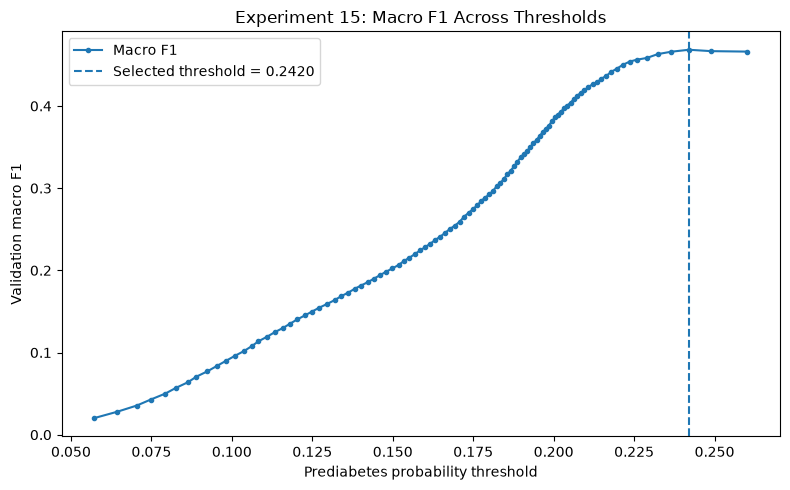

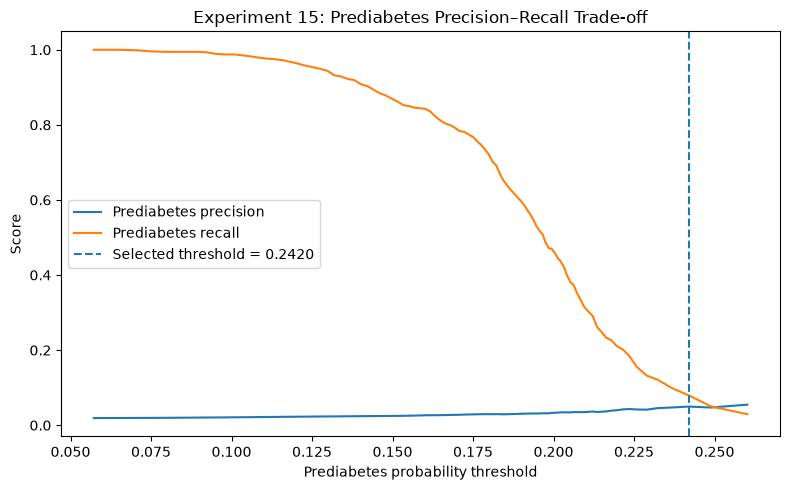

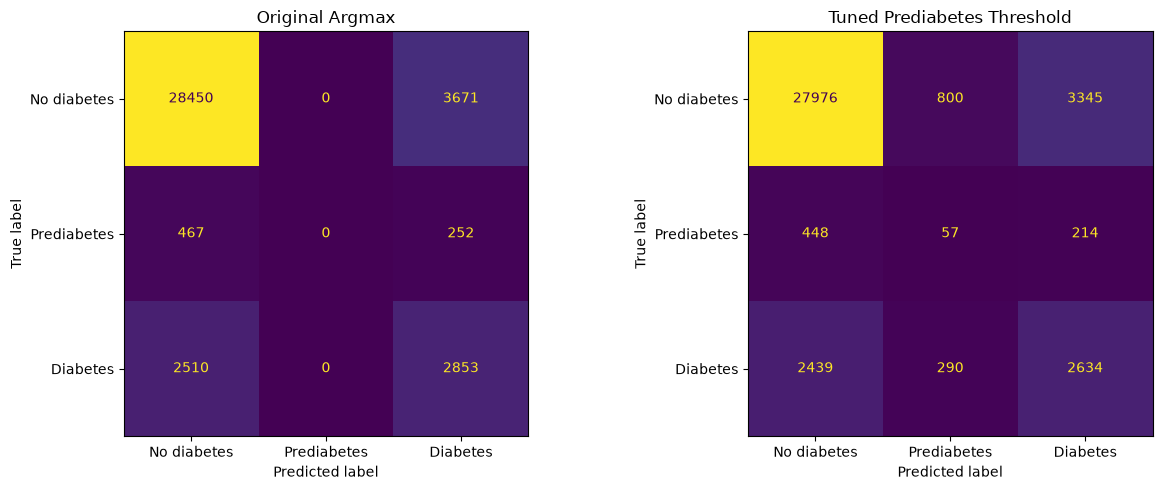

In [81]:
# Plot1: Macro F1 across thresholds
threshold_plot = threshold_results.sort_values("threshold")

plt.figure(figsize=(8, 5))
plt.plot(
    threshold_plot["threshold"],
    threshold_plot["macro_f1"],
    marker=".",
    label="Macro F1"
)
plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.4f}"
)
plt.xlabel("Prediabetes probability threshold")
plt.ylabel("Validation macro F1")
plt.title("Experiment 15: Macro F1 Across Thresholds")
plt.legend()
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "experiment_15_macro_f1_thresholds.png",
    dpi=150
)
plt.show()


# Plot2: Precision and recall for prediabetes
plt.figure(figsize=(8, 5))
plt.plot(
    threshold_plot["threshold"],
    threshold_plot["prediabetes_precision"],
    label="Prediabetes precision"
)
plt.plot(
    threshold_plot["threshold"],
    threshold_plot["prediabetes_recall"],
    label="Prediabetes recall"
)
plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.4f}"
)
plt.xlabel("Prediabetes probability threshold")
plt.ylabel("Score")
plt.title("Experiment 15: Prediabetes Precision–Recall Trade-off")
plt.legend()
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "experiment_15_precision_recall_thresholds.png",
    dpi=150
)
plt.show()


# Plot 3: Compare confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_val_array, baseline_predictions, labels=[0, 1, 2]
    ),
    display_labels=CLASS_NAMES
).plot(ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title("Original Argmax")

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_val_array, best_threshold_predictions, labels=[0, 1, 2]
    ),
    display_labels=CLASS_NAMES
).plot(ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("Tuned Prediabetes Threshold")

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "experiment_15_confusion_matrices.png",
    dpi=150
)
plt.show()

The confusion matrices confirm that the tuned model correctly identified 57 prediabetes cases, compared with zero under the original decision rule. However, it incorrectly labelled 1,090 people from the other two classes as having prediabetes. This explains the low precision. The macro F1 curve peaks around a threshold of 0.2420, illustrating the trade-off between detecting more prediabetes cases and making more false-positive predictions.

In [82]:
threshold_config = {
    "experiment": "Experiment 15 Prediabetes Threshold Tuning",
    "base_model": "Experiment 13 Deeper MLP with Focal Loss",
    "method": "Prediabetes threshold; otherwise choose class 0 or 2",
    "selection_metric": "Validation Macro F1",
    "threshold_candidates": int(len(threshold_candidates)),
    "test_set_used": False
}

run = wandb.init(
    project=WANDB_PROJECT,
    name="Experiment 15 Prediabetes Threshold Tuning",
    mode=WANDB_MODE,
    config=threshold_config,
    reinit="finish_previous"
)

try:
    wandb.log({
        "baseline/accuracy": baseline_metrics["accuracy"],
        "baseline/macro_f1": baseline_metrics["macro_f1"],
        "baseline/prediabetes_recall":
            baseline_metrics["prediabetes_recall"],
        "baseline/prediabetes_precision":
            baseline_metrics["prediabetes_precision"],
        "tuned/threshold": best_threshold,
        "tuned/accuracy": float(best_row["accuracy"]),
        "tuned/macro_f1": float(best_row["macro_f1"]),
        "tuned/weighted_f1": float(best_row["weighted_f1"]),
        "tuned/prediabetes_precision":
            float(best_row["prediabetes_precision"]),
        "tuned/prediabetes_recall":
            float(best_row["prediabetes_recall"]),
        "tuned/prediabetes_f1":
            float(best_row["prediabetes_f1"]),
        "threshold_sweep": wandb.Table(dataframe=threshold_results)
    })

    # Save the full threshold sweep locally.
    threshold_results.to_csv(
        RESULTS_DIR / "experiment_15_threshold_sweep.csv",
        index=False
    )

finally:
    wandb.finish()

print(f"Selected threshold: {best_threshold:.5f}")
print("Threshold results and plots saved in:", RESULTS_DIR.resolve())

baseline/accuracy,▁
baseline/macro_f1,▁
baseline/prediabetes_precision,▁
baseline/prediabetes_recall,▁
tuned/accuracy,▁
tuned/macro_f1,▁
tuned/prediabetes_f1,▁
tuned/prediabetes_precision,▁
tuned/prediabetes_recall,▁
tuned/threshold,▁
+1,...


Selected threshold: 0.24203
Threshold results and plots saved in: /home/janviere-munezero/Documents/ML/Introduction to ML/diabetes-risk-prediction/results


**Interpretation:** Lowering the prediabetes decision threshold increased its recall from 0% to 7.93% and improved macro F1 from 0.4551 to 0.4684. However, prediabetes precision remained very low at 4.97%, meaning that most predictions of this class were incorrect. Accuracy also decreased from 81.94% to 80.27%, while diabetes recall fell from 53.20% to 49.11%. Therefore, threshold tuning produced a modest improvement in overall class balance but did not adequately solve prediabetes detection.

### Experiment 16: Regularized MLP with Batch Normalization and L2 Regularization

In Experiment 13, the deeper MLP achieved a validation macro F1-score of 0.4551 and a diabetes recall of 53.20%, but it failed to identify any prediabetes cases using the default prediction rule. In this experiment, we will improve the network by adding Batch Normalization and L2 regularization while keeping the same three hidden layers, focal loss, adjusted class weights, and train-validation split.

Batch Normalization helps stabilize the activations during training, while L2 regularization penalizes excessively large weights to reduce the risk of overfitting. We will use the training and validation learning curves, macro F1-score, confusion matrix, and per-class precision and recall to evaluate whether these changes improve generalization and minority-class detection.

In [83]:
# Regularized MLP with Batch Normalization and L2

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)

L2_STRENGTH = 1e-4

regularized_mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_dl.shape[1],)),

    tf.keras.layers.Dense(
        256,
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(L2_STRENGTH)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        128,
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(L2_STRENGTH)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        64,
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(L2_STRENGTH)
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(3, activation="softmax")
])

regularized_mlp.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=make_focal_loss(sqrt_class_weight_dict, gamma=2.0),
    metrics=["accuracy"]
)

regularized_mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         5,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,323 (188.76 KB)

 Trainable params: 47,427 (185.26 KB)

 Non-trainable params: 896 (3.50 KB)

In [84]:
regularized_mlp_config = {
    "model": "Regularized MLP with Batch Normalization",
    "hidden_layers": [256, 128, 64],
    "activation": "relu",
    "batch_normalization": True,
    "l2_strength": L2_STRENGTH,
    "dropout_rates": [0.3, 0.3, 0.2],
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "Focal Loss",
    "focal_gamma": 2.0,
    "class_weighting": "normalized_inverse_square_root",
    "batch_size": BATCH_SIZE,
    "max_epochs": 30,
    "early_stopping_patience": 4,
    "random_state": RANDOM_STATE
}

regularized_mlp_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

(
    regularized_mlp,
    history_16,
    metrics_16,
    report_16
) = train_evaluate_keras(
    model=regularized_mlp,
    train_ds=train_ds,
    val_ds=val_ds,
    X_val=X_val_dl,
    y_val=y_val,
    experiment_name="Experiment 16 Regularized MLP with Batch Normalization and L2",
    config=regularized_mlp_config,
    class_weight=None,
    epochs=30,
    callbacks=regularized_mlp_callbacks,
    history_filename="experiment_16_regularized_mlp_history.csv"
)

Epoch 1/30


/home/janviere-munezero/miniconda3/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


347/347 ━━━━━━━━━━━━━━━━━━━━ 20s 35ms/step - accuracy: 0.7498 - loss: 0.1730 - val_accuracy: 0.8006 - val_loss: 0.1452 - learning_rate: 0.0010
Epoch 2/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.8037 - loss: 0.1448 - val_accuracy: 0.7938 - val_loss: 0.1398 - learning_rate: 0.0010
Epoch 3/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.8091 - loss: 0.1377 - val_accuracy: 0.8047 - val_loss: 0.1346 - learning_rate: 0.0010
Epoch 4/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8114 - loss: 0.1326 - val_accuracy: 0.8112 - val_loss: 0.1303 - learning_rate: 0.0010
Epoch 5/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.8109 - loss: 0.1282 - val_accuracy: 0.8056 - val_loss: 0.1277 - learning_rate: 0.0010
Epoch 6/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.8125 - loss: 0.1252 - val_accuracy: 0.8112 - val_loss: 0.1244 - learning_rate: 0.0010
Epoch 7/30
347/347 ━━━━━━━━━━━━━━━━━━━━ 13s 38ms/step - accuracy: 0.8132 - loss: 0.1223

,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC
0,0.8248,0.4551,0.8214,0.4447,0.4673,0.7734



PER-CLASS VALIDATION METRICS


,Class,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,No diabetes,0.9017,0.8966,0.8992,0.8244,0.9598
1,Prediabetes,0.0000,0.0000,0.0000,0.6682,0.0331
2,Diabetes,0.4325,0.5053,0.4661,0.8276,0.4301



Training history saved to: results/experiment_16_regularized_mlp_history.csv


epoch/accuracy,▁▆▇▇▇▇▇▇██████████████
epoch/learning_rate,███████████████▃▃▃▃▃▁▁
epoch/loss,█▅▄▃▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch/number,▁▁▂▂▂▃▃▃▄▄▄▅▅▅▆▆▆▇▇▇██
epoch/val_accuracy,▂▁▃▄▃▄▆▆▄▆█▅▆▅▄▇▄▇▆▇▆▆
epoch/val_loss,█▇▅▄▄▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
summary/best_epoch,▁
summary/best_validation_loss,▁
summary/epochs_completed,▁
validation/Diabetes_average_precision,▁
+20,...


**Interpretation:** Adding Batch Normalization and L2 regularization increased accuracy from 81.94% to 82.48%, while macro F1 remained at 0.4551. The validation loss decreased until epoch 18, suggesting steady learning without obvious strong overfitting in the displayed curves. However, prediabetes recall remained at 0%, and diabetes recall decreased from 53.20% to 50.53%. Therefore, the additional regularization did not meaningfully improve minority-class detection. Experiment 16 offers slightly better accuracy but does not outperform Experiment 13 on macro F1 or diabetes recall.

In [85]:
# Ensure the results directory exists
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_LABELS = [0, 1, 2]
CLASS_NAMES = ["No diabetes", "Prediabetes", "Diabetes"]

y_validation = np.asarray(y_val).astype(int)


def get_probabilities(model, X, is_keras=False):
    """Return predicted probabilities in class order 0, 1, 2."""
    if is_keras:
        probabilities = model.predict(X, verbose=0)
    else:
        probabilities = model.predict_proba(X)
        model_classes = list(model.classes_)
        probabilities = probabilities[
            :, [model_classes.index(label) for label in CLASS_LABELS]
        ]

    return np.asarray(probabilities)


def calculate_validation_metrics(
    y_true,
    probabilities,
    predictions=None
):
    """Calculate consistent overall and per-class validation metrics."""
    if predictions is None:
        predictions = np.argmax(probabilities, axis=1)

    report = classification_report(
        y_true,
        predictions,
        labels=CLASS_LABELS,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    y_binary = label_binarize(y_true, classes=CLASS_LABELS)

    metrics = {
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro F1": f1_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, predictions, average="weighted", zero_division=0
        ),
        "Macro Precision": precision_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Macro ROC-AUC": roc_auc_score(
            y_true,
            probabilities,
            labels=CLASS_LABELS,
            multi_class="ovr",
            average="macro"
        )
    }

    for i, name in enumerate(CLASS_NAMES):
        metrics[f"{name} Precision"] = report[name]["precision"]
        metrics[f"{name} Recall"] = report[name]["recall"]
        metrics[f"{name} F1"] = report[name]["f1-score"]
        metrics[f"{name} ROC-AUC"] = roc_auc_score(
            y_binary[:, i], probabilities[:, i]
        )
        metrics[f"{name} Average Precision"] = average_precision_score(
            y_binary[:, i], probabilities[:, i]
        )

    return metrics


# Experiment number, name, family, configuration, model, input data, Keras?
experiment_specs = [
    (1, "Logistic Regression baseline", "Traditional ML",
     "LR; max_iter=1000", model_1, X_val_processed, False),

    (2, "Logistic Regression balanced", "Traditional ML",
     "LR; class_weight=balanced", model_2, X_val_processed, False),

    (3, "Random Forest balanced", "Traditional ML",
     "200 trees; min_leaf=2; balanced weights",
     model_3, X_val_processed, False),

    (4, "Random Forest tuned", "Traditional ML",
     "200 trees; max_depth=20; min_leaf=5; balanced weights",
     model_4, X_val_processed, False),

    (5, "Gradient Boosting baseline", "Traditional ML",
     "100 estimators; learning_rate=0.1; depth=3",
     model_5, X_val_processed, False),

    (6, "Gradient Boosting balanced", "Traditional ML",
     "Gradient Boosting; balanced sample weights",
     model_6, X_val_processed, False),

    (7, "CatBoost balanced", "Traditional ML",
     "500 iterations; depth=6; learning_rate=0.05; balanced",
     catboost_model, X_val_processed, False),

    (8, "CatBoost tuned", "Traditional ML",
     "500 iterations; depth=8; learning_rate=0.05; balanced",
     model_8, X_val_processed, False),

    (9, "Baseline MLP with balanced weights", "Deep learning",
     "Dense [128,64]; dropout [0.3,0.2]; balanced weights",
     dl_model, X_val_dl, True),

    (10, "MLP without class weights", "Deep learning",
     "Dense [128,64]; dropout [0.3,0.2]; no class weights",
     mlp_unweighted, X_val_dl, True),

    (11, "MLP with adjusted class weights", "Deep learning",
     "Dense [128,64]; inverse-square-root class weights",
     mlp_sqrt, X_val_dl, True),

    (12, "MLP with focal loss", "Deep learning",
     "Dense [128,64]; focal loss; gamma=2",
     focal_model, X_val_dl, True),

    (13, "Deeper MLP with focal loss", "Deep learning",
     "Dense [256,128,64]; focal loss; gamma=2",
     deep_mlp_model, X_val_dl, True),

    (14, "MLP with random oversampling", "Deep learning",
     "Dense [128,64]; random oversampling",
     oversampling_model, X_val_dl, True),

    (16, "Regularized MLP", "Deep learning",
     "Dense [256,128,64]; Batch Normalization; L2=0.0001",
     regularized_mlp, X_val_dl, True),
]


# Best epochs, where a training history is available
history_by_experiment = {
    9: history_9,
    10: history_10,
    11: history_11,
    12: focal_history,
    13: deep_mlp_history,
    14: oversampling_history,
    16: history_16
}


def find_best_epoch(training_history):
    """Get the epoch with the lowest validation loss."""
    history_data = getattr(training_history, "history", {})
    validation_losses = history_data.get("val_loss")

    if validation_losses is None:
        return np.nan

    return int(np.argmin(validation_losses) + 1)


# Re-evaluate the trained models on the same validation split
master_rows = []

for number, name, family, config, model, X_val, is_keras in experiment_specs:
    probabilities = get_probabilities(model, X_val, is_keras)

    metrics = calculate_validation_metrics(
        y_validation, probabilities
    )

    master_rows.append({
        "Experiment": number,
        "Name": name,
        "Family": family,
        "Configuration": config,
        "Validation split": "Same held-out validation set",
        "Best epoch": find_best_epoch(
            history_by_experiment[number]
        ) if number in history_by_experiment else np.nan,
        **metrics
    })


# Experiment 15 is a changed decision rule applied to Experiment 13.
# It is not a separately trained neural network.
deep_probabilities = get_probabilities(
    deep_mlp_model, X_val_dl, is_keras=True
)

threshold_metrics = calculate_validation_metrics(
    y_validation,
    deep_probabilities,
    predictions=best_threshold_predictions
)

master_rows.append({
    "Experiment": 15,
    "Name": "Experiment 13 + tuned prediabetes threshold",
    "Family": "Decision-rule analysis",
    "Configuration": f"Prediabetes threshold={best_threshold:.5f}; no retraining",
    "Validation split": "Same held-out validation set",
    "Best epoch": np.nan,
    **threshold_metrics
})


# Sort numerically and save the table
master_results = (
    pd.DataFrame(master_rows)
    .sort_values("Experiment")
    .reset_index(drop=True)
)

master_results.to_csv(
    RESULTS_DIR / "master_experiment_results.csv",
    index=False
)

print("Master results: Experiments from 1 to 16")
display(
    master_results[
        [
            "Experiment",
            "Name",
            "Family",
            "Configuration",
            "Accuracy",
            "Macro F1",
            "Weighted F1",
            "Prediabetes Precision",
            "Prediabetes Recall",
            "Diabetes Recall",
            "Macro ROC-AUC",
            "Best epoch"
        ]
    ].round(4)
)

print(
    "\nFull results saved to:",
    (RESULTS_DIR / "master_experiment_results.csv").resolve()
)

Master results: Experiments from 1 to 16


,Experiment,Name,Family,Configuration,Accuracy,Macro F1,Weighted F1,Prediabetes Precision,Prediabetes Recall,Diabetes Recall,Macro ROC-AUC,Best epoch
0,1,Logistic Regression baseline,Traditional ML,LR; max_iter=1000,0.8454,0.3936,0.8066,0.0000,0.0000,0.1779,0.7807,NaN
1,2,Logistic Regression balanced,Traditional ML,LR; class_weight=balanced,0.6475,0.4281,0.7215,0.0302,0.2907,0.5890,0.7720,NaN
2,3,Random Forest balanced,Traditional ML,200 trees; min_leaf=2; balanced weights,0.7583,0.4428,0.7810,0.0285,0.0139,0.6782,0.7572,NaN
3,4,Random Forest tuned,Traditional ML,200 trees; max_depth=20; min_leaf=5; balanced ...,0.7146,0.4327,0.7527,0.0236,0.0403,0.7313,0.7607,NaN
4,5,Gradient Boosting baseline,Traditional ML,100 estimators; learning_rate=0.1; depth=3,0.8483,0.4021,0.8112,0.0000,0.0000,0.1960,0.7881,NaN
5,6,Gradient Boosting balanced,Traditional ML,Gradient Boosting; balanced sample weights,0.6232,0.4230,0.7035,0.0317,0.3408,0.6161,0.7739,NaN
6,7,CatBoost balanced,Traditional ML,500 iterations; depth=6; learning_rate=0.05; b...,0.6387,0.4231,0.7130,0.0293,0.2684,0.6260,0.7715,NaN
7,8,CatBoost tuned,Traditional ML,500 iterations; depth=8; learning_rate=0.05; b...,0.6659,0.4296,0.7275,0.0293,0.1864,0.6780,0.7612,NaN
8,9,Baseline MLP with balanced weights,Deep learning,"Dense [128,64]; dropout [0.3,0.2]; balanced we...",0.6613,0.4260,0.7182,0.0306,0.1446,0.7557,0.7678,3.0
9,10,MLP without class weights,Deep learning,"Dense [128,64]; dropout [0.3,0.2]; no class we...",0.8485,0.3913,0.8069,0.0000,0.0000,0.1656,0.7881,17.0



Full results saved to: /home/janviere-munezero/Documents/ML/Introduction to ML/diabetes-risk-prediction/results/master_experiment_results.csv


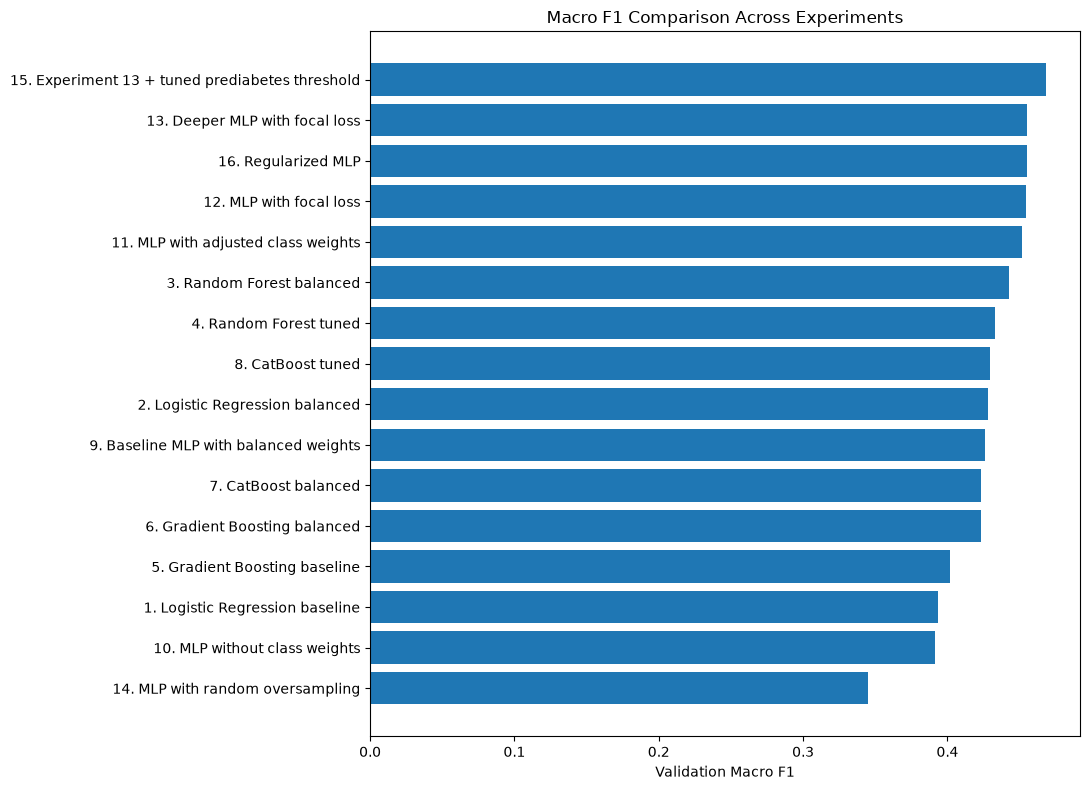

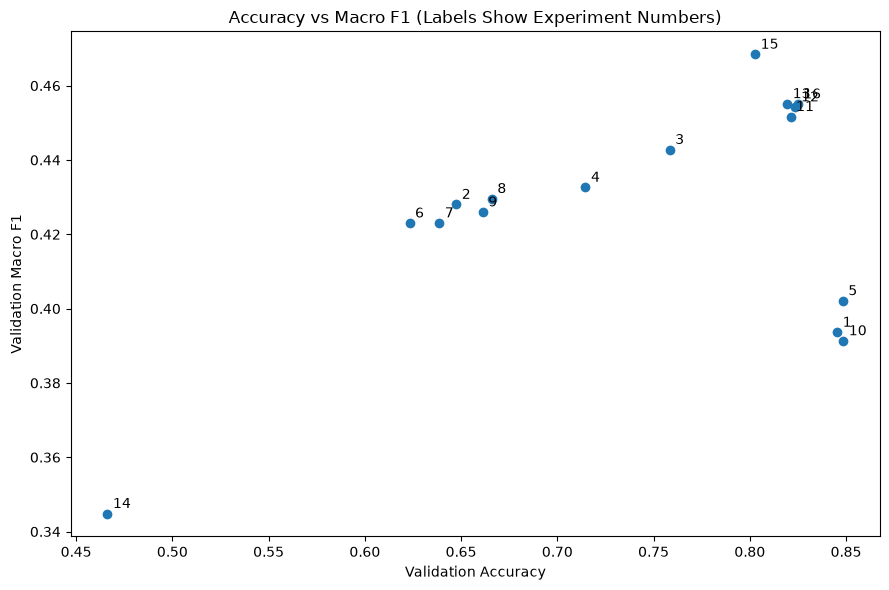

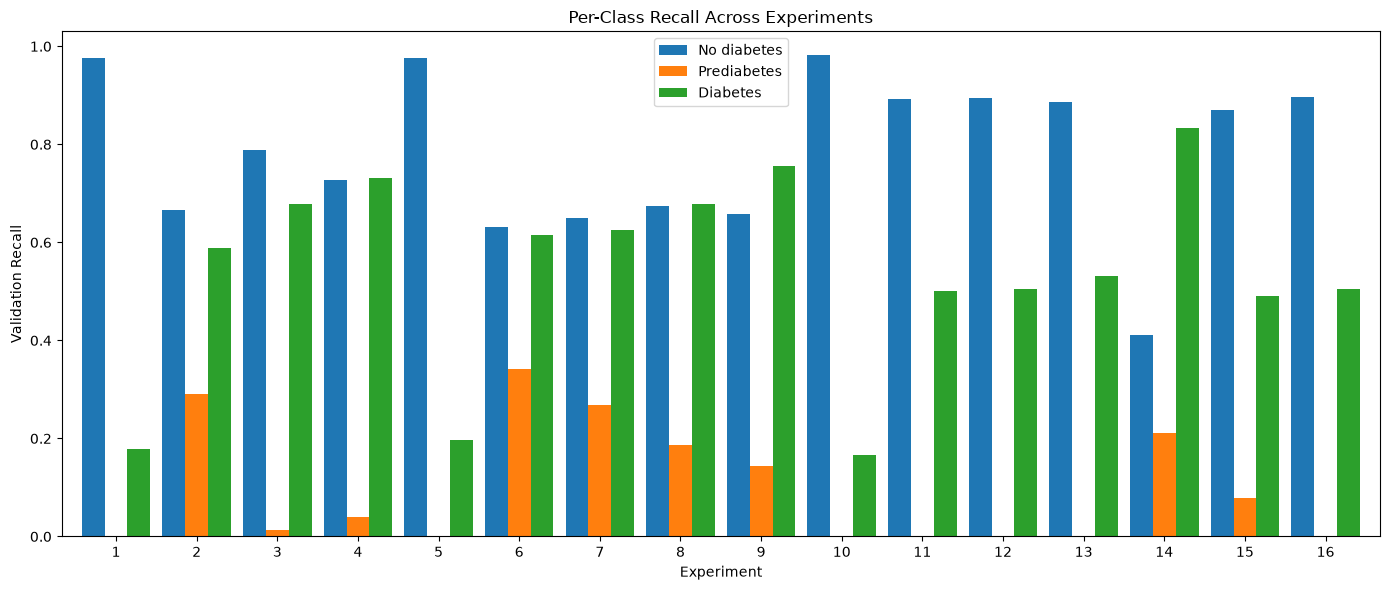

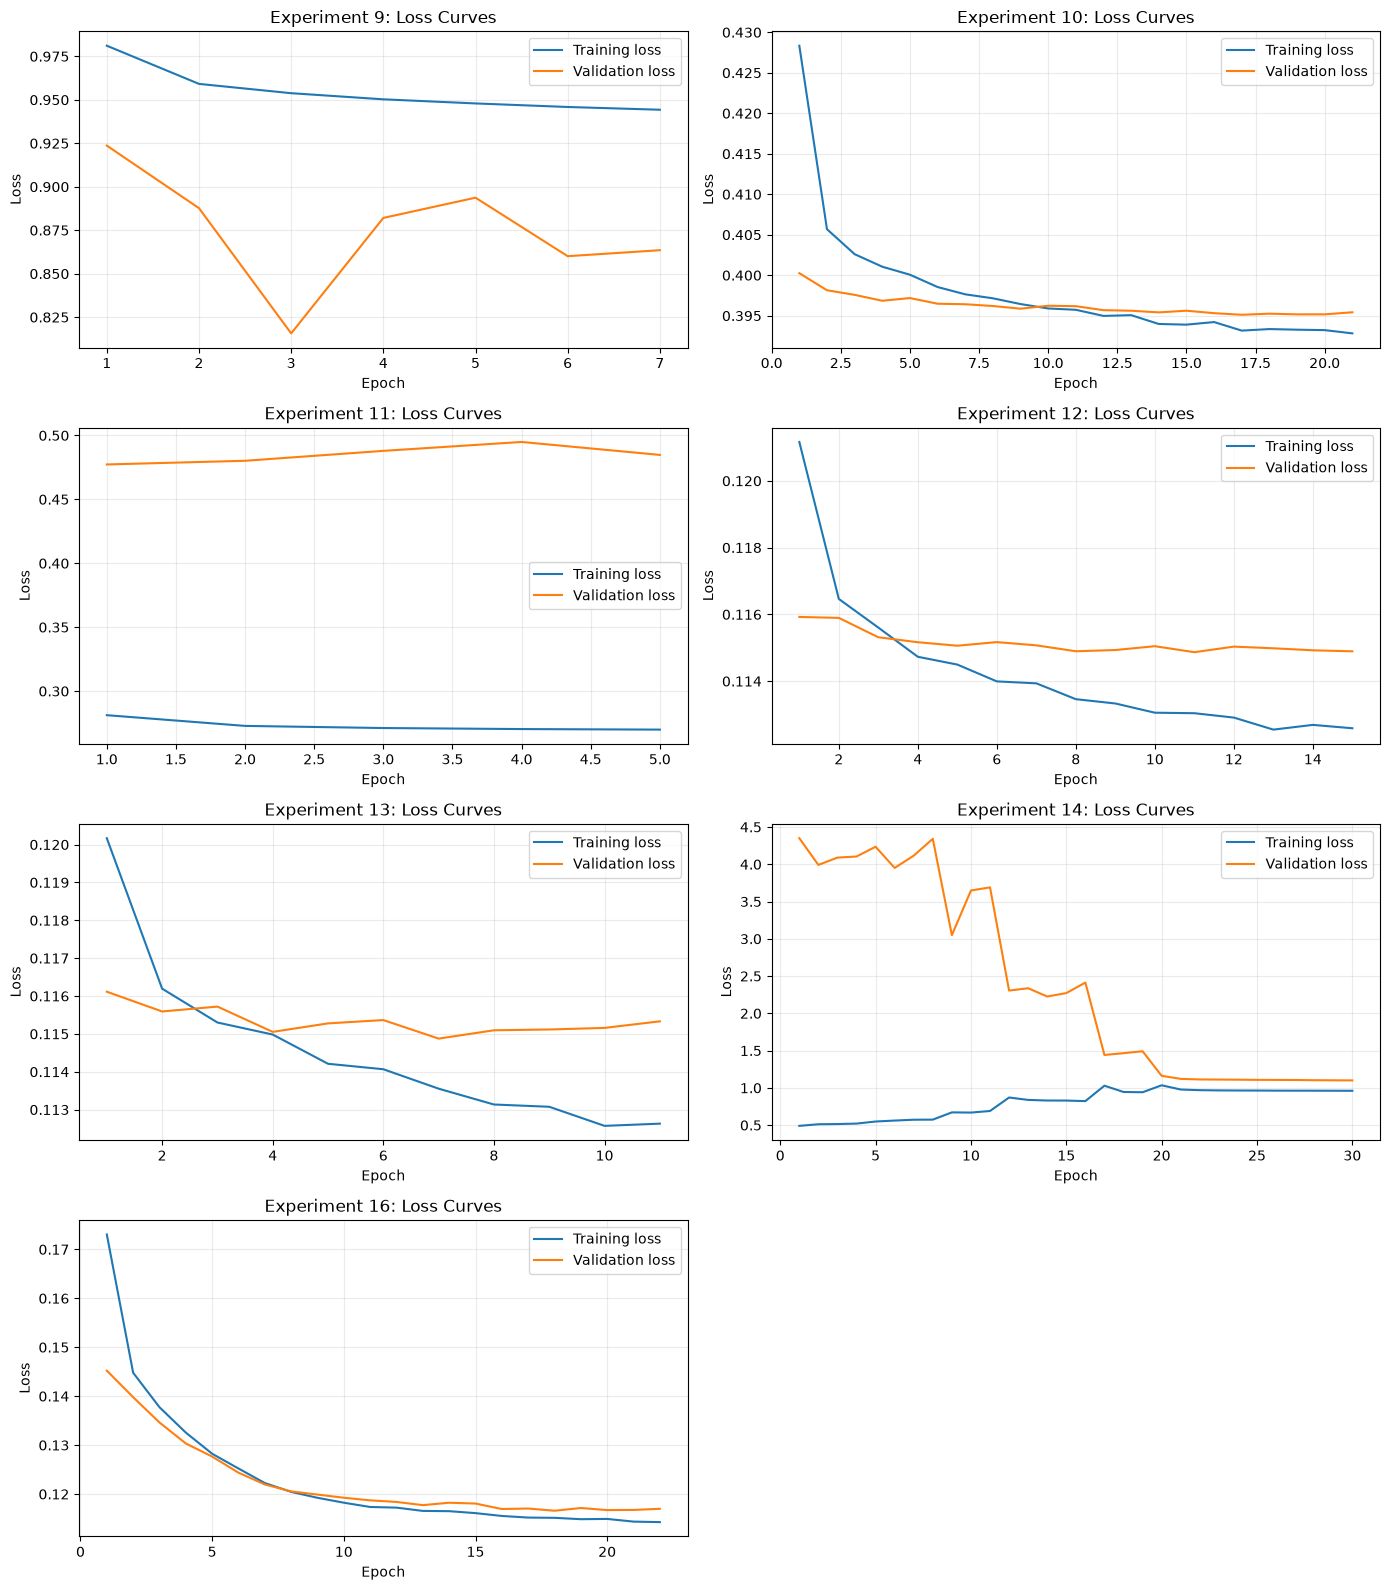

Plots saved in: /home/janviere-munezero/Documents/ML/Introduction to ML/diabetes-risk-prediction/results


In [86]:
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

# Compare macro F1 across all experiments
plot_data = master_results.sort_values("Macro F1")

plt.figure(figsize=(11, 8))
plt.barh(
    plot_data["Experiment"].astype(str) + ". " + plot_data["Name"],
    plot_data["Macro F1"]
)
plt.xlabel("Validation Macro F1")
plt.title("Macro F1 Comparison Across Experiments")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparison_macro_f1.png", dpi=150)
plt.show()


# Compare accuracy and macro F1
plt.figure(figsize=(9, 6))
plt.scatter(
    master_results["Accuracy"],
    master_results["Macro F1"]
)

for _, row in master_results.iterrows():
    plt.annotate(
        str(int(row["Experiment"])),
        (row["Accuracy"], row["Macro F1"]),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.xlabel("Validation Accuracy")
plt.ylabel("Validation Macro F1")
plt.title("Accuracy vs Macro F1 (Labels Show Experiment Numbers)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparison_accuracy_vs_macro_f1.png", dpi=150)
plt.show()


# Compare recall for each class
recall_columns = [
    "No diabetes Recall",
    "Prediabetes Recall",
    "Diabetes Recall"
]

recall_data = master_results.set_index("Experiment")[recall_columns]
ax = recall_data.plot(kind="bar", figsize=(14, 6), width=0.85)

ax.set_xlabel("Experiment")
ax.set_ylabel("Validation Recall")
ax.set_title("Per-Class Recall Across Experiments")
ax.legend([
    "No diabetes",
    "Prediabetes",
    "Diabetes"
])
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparison_class_recall.png", dpi=150)
plt.show()


# Plot training and validation loss for neural-network experiments
histories = {
    9: history_9,
    10: history_10,
    11: history_11,
    12: focal_history,
    13: deep_mlp_history,
    14: oversampling_history,
    16: history_16
}

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for ax, (exp_number, hist) in zip(axes, histories.items()):
    history_data = hist.history

    if "loss" in history_data:
        ax.plot(
            range(1, len(history_data["loss"]) + 1),
            history_data["loss"],
            label="Training loss"
        )

    if "val_loss" in history_data:
        ax.plot(
            range(1, len(history_data["val_loss"]) + 1),
            history_data["val_loss"],
            label="Validation loss"
        )

    ax.set_title(f"Experiment {exp_number}: Loss Curves")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.25)

# Hide the unused eighth panel
for i in range(len(histories), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "neural_network_learning_curves.png", dpi=150)
plt.show()

print("Plots saved in:", RESULTS_DIR.resolve())

## Interpretation of Experiment Comparison Plots

### 1. Macro F1 Comparison Across Experiments

Experiment 15 achieved the highest validation macro F1-score of **0.4684**, followed by Experiments 13 and 16, both at **0.4551**. The balanced Random Forest (Experiment 3) was the strongest traditional machine-learning model, achieving a macro F1-score of **0.4428**.

However, Experiment 15 adjusted the prediction threshold of Experiment 13 rather than training a new model. Although this increased macro F1, prediabetes precision remained low at 4.97%. Therefore, this improvement must be interpreted alongside the high number of false-positive predictions.

### 2. Accuracy Versus Macro F1

Experiments 1, 5, and 10 achieved relatively high accuracy, ranging from approximately 84.5% to 84.9%, but their macro F1-scores remained between 0.391 and 0.402. These models performed well on the majority class, no diabetes, but failed to identify prediabetes.

In contrast, class-weighted and focal-loss approaches generally improved the balance between class-specific performance, although some reduced overall accuracy. This demonstrates why accuracy alone is insufficient for this imbalanced dataset. Macro F1 provides a more balanced assessment because it gives equal importance to each class's F1-score.

### 3. Per-Class Recall Across Experiments

The recall plot reveals that prediabetes is consistently the most difficult class to identify. Class weighting and oversampling increased prediabetes recall in some experiments, but these improvements often came with reduced precision or weaker performance on other classes.

For example, Experiment 14 achieved diabetes recall of **83.31%**, but its accuracy fell to 46.62% and macro F1 to 0.3449. This suggests that the model detected more diabetes cases at the cost of many incorrect predictions. Experiment 15 also improved prediabetes recall from 0% to 7.93%, but its precision was only 4.97%.

These findings show that improving recall alone is not enough; precision, macro F1, and the confusion matrix must also be considered.

### 4. Learning-Curve Analysis

The training and validation loss curves help explain how the neural networks learned and whether their performance generalized to unseen validation examples.

- **Experiment 9 Baseline MLP with balanced weights:** Training loss decreased, but validation loss fluctuated considerably. This suggests unstable validation performance and indicates that class weighting did not automatically produce reliable generalization.

- **Experiment 10 MLP without class weights:** Training and validation losses decreased and remained close. The curves show no strong evidence of overfitting, but the model still failed to identify prediabetes. This demonstrates that stable learning does not guarantee balanced classification performance.

- **Experiment 11  MLP with adjusted class weights:** Training loss remained much lower than validation loss, suggesting a substantial generalization gap. However, because class weighting affects the training objective, the loss difference should not be interpreted as proof of overfitting on its own.

- **Experiments 12 and 13 Focal-loss MLPs:** Training loss continued to decrease while validation loss largely plateaued or fluctuated slightly. This suggests diminishing validation improvements and possible mild overfitting in later epochs. Early stopping helps prevent unnecessary training beyond the point of best validation performance.

- **Experiment 14  MLP with random oversampling:** The training and validation losses were high and unstable, consistent with its poor validation metrics. Oversampling changed the class distribution seen during training, and the model struggled to perform effectively on the original validation distribution.

- **Experiment 16  Regularized MLP:** Training and validation losses decreased together and remained relatively close. Batch Normalization and L2 regularization supported stable learning, but macro F1 remained at 0.4551, and prediabetes recall remained zero. Thus, more regularization did not resolve the main classification weakness.

One important limitation is that the loss values are not directly comparable across all experiments. Some models used ordinary cross-entropy, while others used focal loss or class weighting. The curves should therefore be interpreted according to their trends within each experiment, alongside the validation metrics, rather than used alone to rank all models.

### 5. Overall Finding

The plots show that handling class imbalance is central to improving this model. More complex architectures, class weighting, focal loss, and oversampling each produced different trade-offs, but none of the trained models adequately identified prediabetes using the default prediction rule. Threshold tuning produced a modest macro F1 improvement, but its low prediabetes precision limits its practical usefulness.

Based on validation macro F1, Experiment 13 remains the strongest trained deep-learning candidate, tied with Experiment 16 at 0.4551. Experiment 3 remains the strongest traditional model at 0.4428. The final choice should be confirmed through evaluation on the untouched test set, with particular attention to class-specific precision, recall, and false-positive errors.


### Confusion matrices

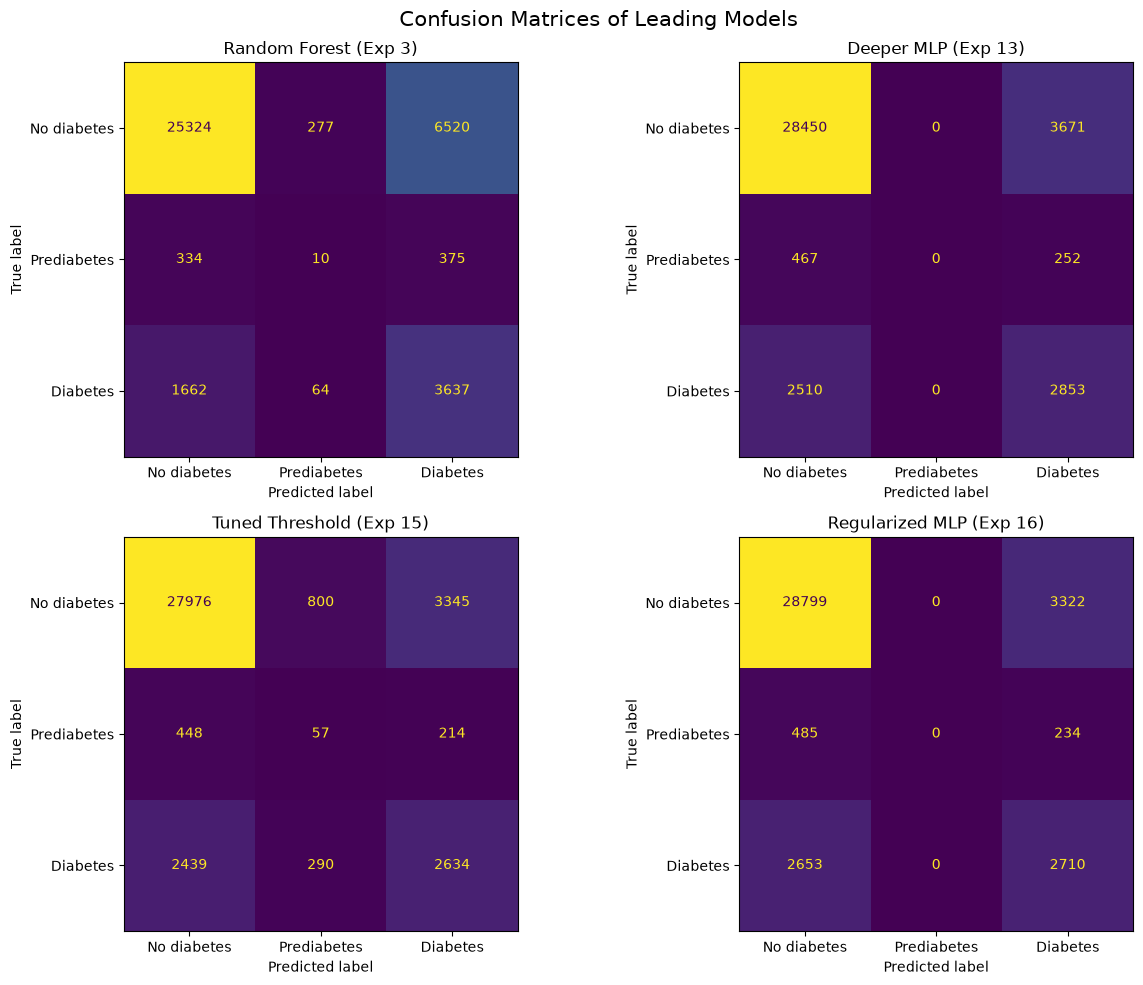

In [87]:
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

y_true = np.asarray(y_val).astype(int)
labels = [0, 1, 2]
class_names = ["No diabetes", "Prediabetes", "Diabetes"]

# Obtain probabilities from the trained models
rf_prob = model_3.predict_proba(X_val_processed)

# Ensure probability columns are ordered as classes 0, 1, 2
rf_prob = rf_prob[
    :, [list(model_3.classes_).index(c) for c in labels]
]

exp13_prob = deep_mlp_model.predict(X_val_dl, verbose=0)
exp16_prob = regularized_mlp.predict(X_val_dl, verbose=0)

# Convert probabilities to class predictions
rf_pred = np.argmax(rf_prob, axis=1)
exp13_pred = np.argmax(exp13_prob, axis=1)
exp16_pred = np.argmax(exp16_prob, axis=1)

# Experiment 15 uses Experiment 13's probabilities
# but applies the tuned prediabetes threshold
exp15_pred = best_threshold_predictions

candidate_predictions = {
    "Random Forest (Exp 3)": rf_pred,
    "Deeper MLP (Exp 13)": exp13_pred,
    "Tuned Threshold (Exp 15)": exp15_pred,
    "Regularized MLP (Exp 16)": exp16_pred
}

# Draw one confusion matrix for each approach
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (name, predictions) in zip(
    axes.flatten(), candidate_predictions.items()
):
    cm = confusion_matrix(y_true, predictions, labels=labels)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    ).plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrices of Leading Models", fontsize=15)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "leading_models_confusion_matrices.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


The confusion matrices show that all four approaches struggle to identify prediabetes. The balanced Random Forest correctly classified only 10 prediabetes cases, while the deeper MLP and regularized MLP failed to identify any. This reflects the difficulty of learning from a class representing only a small proportion of the dataset.

Experiment 15's tuned threshold correctly identified 57 prediabetes cases, increasing recall from 0% to 7.93%. However, it also produced many false positives, resulting in prediabetes precision of only 4.97%. The deeper MLP performed better at identifying no-diabetes cases, while the Random Forest achieved higher diabetes recall (67.82%) than Experiments 13 and 16.

Overall, the results demonstrate a trade-off between detecting minority classes and avoiding incorrect predictions. Threshold tuning improved prediabetes detection slightly, but further improvements are needed.

### ROC and precision recall curves

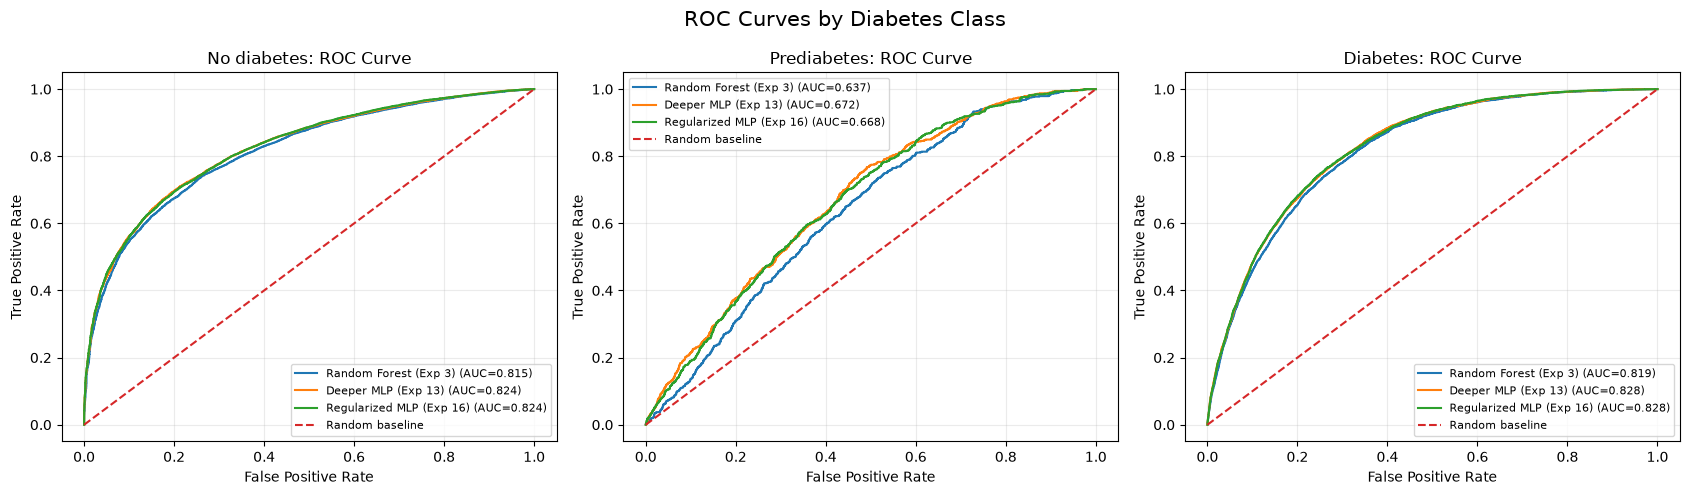

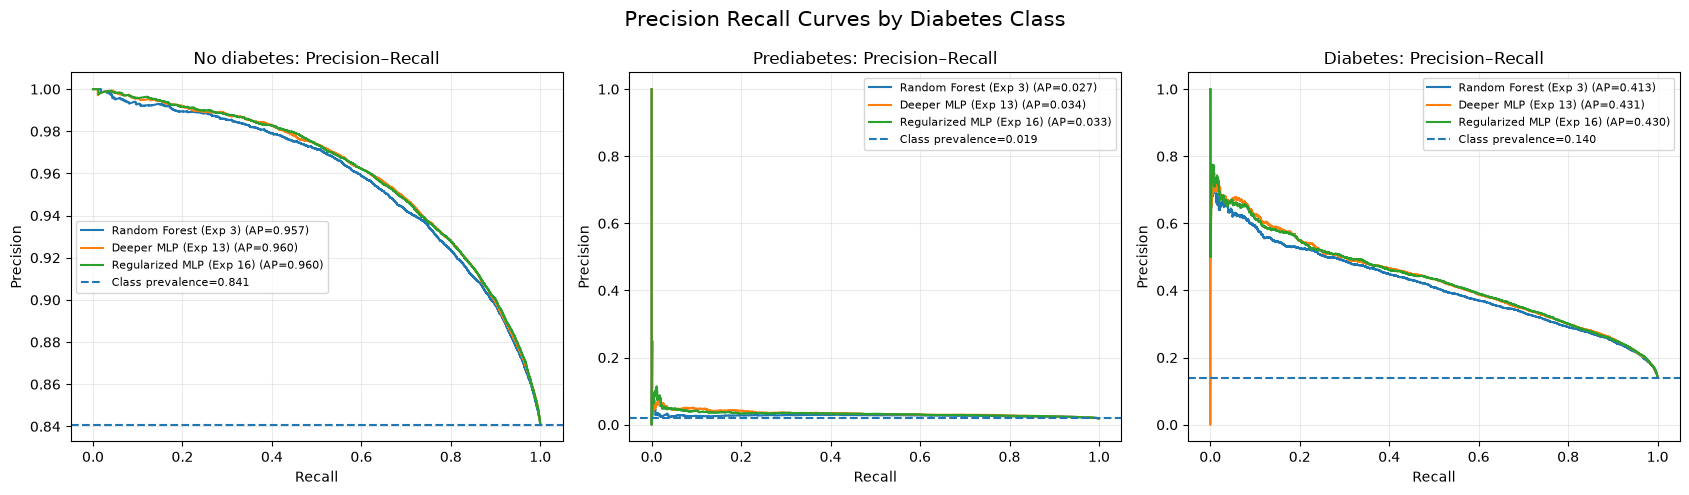

ROC and precision-recall plots saved in: /home/janviere-munezero/Documents/ML/Introduction to ML/diabetes-risk-prediction/results


In [88]:
# ROC and precision-recall curves
# Convert the true labels into one-vs-rest binary labels
y_binary = label_binarize(y_true, classes=labels)

# Probability outputs for the trained models
candidate_probabilities = {
    "Random Forest (Exp 3)": rf_prob,
    "Deeper MLP (Exp 13)": exp13_prob,
    "Regularized MLP (Exp 16)": exp16_prob
}

# Plot1: ROC curves

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for class_idx, ax in enumerate(axes):

    for name, probabilities in candidate_probabilities.items():
        fpr, tpr, _ = roc_curve(
            y_binary[:, class_idx],
            probabilities[:, class_idx]
        )

        roc_auc = auc(fpr, tpr)

        ax.plot(
            fpr,
            tpr,
            label=f"{name} (AUC={roc_auc:.3f})"
        )

    ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
    ax.set_title(f"{class_names[class_idx]}: ROC Curve")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.suptitle("ROC Curves by Diabetes Class", fontsize=15)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "leading_models_roc_curves.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# Plot 2: Precision-recall curves

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for class_idx, ax in enumerate(axes):

    # Baseline precision equals the class's prevalence
    prevalence = y_binary[:, class_idx].mean()

    for name, probabilities in candidate_probabilities.items():
        precision, recall, _ = precision_recall_curve(
            y_binary[:, class_idx],
            probabilities[:, class_idx]
        )

        ap = average_precision_score(
            y_binary[:, class_idx],
            probabilities[:, class_idx]
        )

        ax.plot(
            recall,
            precision,
            label=f"{name} (AP={ap:.3f})"
        )

    ax.axhline(
        prevalence,
        linestyle="--",
        label=f"Class prevalence={prevalence:.3f}"
    )

    ax.set_title(f"{class_names[class_idx]}: Precision–Recall")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.suptitle("Precision Recall Curves by Diabetes Class", fontsize=15)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "leading_models_precision_recall_curves.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("ROC and precision-recall plots saved in:", RESULTS_DIR.resolve())


The results show that all three models distinguish no-diabetes cases relatively well, with ROC-AUC values above 0.81 and Average Precision around 0.96. For diabetes, the deeper MLP (Experiment 13) performed slightly better than the Random Forest, achieving an ROC-AUC of 0.8275 and Average Precision of 0.4310.

Prediabetes remains the most challenging class. Its ROC-AUC ranged from 0.6371 to 0.6723, while Average Precision remained low at 0.0273–0.0339. Although these Average Precision values exceed the class prevalence of 1.88%, the models' ability to identify prediabetes is still weak. This explains why reasonable ROC-AUC values do not guarantee correct predictions using the default `argmax` rule.

Overall, Experiment 13 provides the strongest combined ROC-AUC and Average Precision results for diabetes and prediabetes among the compared models. However, further improvement in prediabetes detection is needed.

In [89]:
best_deep_model = deep_mlp_model
# Save the preprocessor separately for use with the neural network
preprocessor_path = MODELS_DIR / "preprocessor.joblib"
joblib.dump(preprocessor, preprocessor_path)

# Save the selected deep-learning model
keras_path = MODELS_DIR / "best_deep_learning_model.keras"
weights_path = MODELS_DIR / "best_deep_learning_model.weights.h5"

best_deep_model.save(keras_path)
best_deep_model.save_weights(weights_path)

# Save selection information and Experiment 15's fixed threshold
metadata = {
    "traditional_model": "Random Forest (Balanced), Experiment 3",
    "traditional_validation_macro_f1": 0.442797,
    "deep_learning_model": "Deeper MLP with Focal Loss, Experiment 13",
    "deep_learning_validation_macro_f1": 0.4551,
    "deep_learning_validation_diabetes_recall": 0.5320,
    "experiment_15_prediabetes_threshold": 0.24203,
    "threshold_selection_split": "Validation",
    "test_set_used_for_selection": False,
    "class_names": CLASS_NAMES,
    "random_state": RANDOM_STATE
}

metadata_path = MODELS_DIR / "model_selection_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(metadata, file, indent=4)

# Verify that the files exist
for path in [
    preprocessor_path,
    keras_path,
    weights_path,
    metadata_path
]:
    print(f"{path}: {'Saved successfully' if path.exists() else 'NOT FOUND'}")

saved_models/preprocessor.joblib: Saved successfully
saved_models/best_deep_learning_model.keras: Saved successfully
saved_models/best_deep_learning_model.weights.h5: Saved successfully
saved_models/model_selection_metadata.json: Saved successfully


In [90]:
# Load the saved model artifacts

MODELS_DIR = Path("saved_models")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

traditional_artifact = joblib.load(
    MODELS_DIR / "best_traditional_model.joblib"
)

test_rf = traditional_artifact["model"]
test_preprocessor = traditional_artifact["preprocessor"]

# compile=False avoids needing to deserialize the custom focal loss
# just to make predictions.
test_mlp = tf.keras.models.load_model(
    MODELS_DIR / "best_deep_learning_model.keras",
    compile=False
)

print("Saved Random Forest loaded.")
print("Saved deep-learning model loaded.")

# Prepare the untouched test data
# X_test contains the original, unprocessed test predictors.
# Transform it using the preprocessor fitted on training data only.
X_test_final = test_preprocessor.transform(X_test)

X_test_mlp = np.asarray(X_test_final, dtype=np.float32)
y_test_final = np.asarray(y_test).astype(int)

labels = [0, 1, 2]
class_names = ["No diabetes", "Prediabetes", "Diabetes"]

print("Test feature shape:", X_test_mlp.shape)
print("Test target shape:", y_test_final.shape)

print("\nTest-set class distribution:")
print(
    pd.Series(y_test_final)
    .value_counts(normalize=True)
    .sort_index()
    .round(4)
)
# 3. Obtain probabilities from both saved models
rf_prob = test_rf.predict_proba(X_test_final)

# Ensure the Random Forest probability columns are ordered 0, 1, 2.
rf_prob = rf_prob[
    :, [list(test_rf.classes_).index(c) for c in labels]
]

mlp_prob = test_mlp.predict(X_test_mlp, verbose=0)

# Default predictions from the MLP
mlp_pred = np.argmax(mlp_prob, axis=1)

# Experiment 15: use the previously selected validation threshold.
# If prediabetes probability reaches the threshold, predict class 1.
threshold = 0.24203

mlp_threshold_pred = np.argmax(mlp_prob[:, [0, 2]], axis=1)
mlp_threshold_pred = np.where(
    mlp_threshold_pred == 0, 0, 2
)

mlp_threshold_pred[
    mlp_prob[:, 1] >= threshold
] = 1
# 4. Calculate overall and per-class test metrics

def evaluate_test_model(y_true, probabilities, predictions, model_name):
    report = classification_report(
        y_true,
        predictions,
        labels=labels,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    y_binary = label_binarize(y_true, classes=labels)

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro F1": f1_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, predictions, average="weighted", zero_division=0
        ),
        "Macro Precision": precision_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Macro ROC-AUC": roc_auc_score(
            y_true,
            probabilities,
            labels=labels,
            multi_class="ovr",
            average="macro"
        )
    }

    for i, name in enumerate(class_names):
        results[f"{name} Precision"] = report[name]["precision"]
        results[f"{name} Recall"] = report[name]["recall"]
        results[f"{name} F1"] = report[name]["f1-score"]
        results[f"{name} ROC-AUC"] = roc_auc_score(
            y_binary[:, i], probabilities[:, i]
        )
        results[f"{name} Average Precision"] = average_precision_score(
            y_binary[:, i], probabilities[:, i]
        )

    return results


test_results = pd.DataFrame([
    evaluate_test_model(
        y_test_final, rf_prob,
        np.argmax(rf_prob, axis=1),
        "Experiment 3 - Balanced Random Forest"
    ),
    evaluate_test_model(
        y_test_final, mlp_prob,
        mlp_pred,
        "Experiment 13 - Deeper MLP"
    ),
    evaluate_test_model(
        y_test_final, mlp_prob,
        mlp_threshold_pred,
        "Experiment 15 - MLP with tuned threshold"
    )
])

# Save all test metrics
test_results.to_csv(
    RESULTS_DIR / "final_test_results.csv",
    index=False
)

print("\nFinal unseen test results")
display(test_results.round(4))

print(
    "\nFull results saved to:",
    (RESULTS_DIR / "final_test_results.csv").resolve()
)

Saved Random Forest loaded.
Saved deep-learning model loaded.
Test feature shape: (38226, 21)
Test target shape: (38226,)

Test-set class distribution:
0    0.8455
1    0.0179
2    0.1366
Name: proportion, dtype: float64

Final unseen test results


,Model,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Macro ROC-AUC,No diabetes Precision,No diabetes Recall,No diabetes F1,...,Prediabetes Precision,Prediabetes Recall,Prediabetes F1,Prediabetes ROC-AUC,Prediabetes Average Precision,Diabetes Precision,Diabetes Recall,Diabetes F1,Diabetes ROC-AUC,Diabetes Average Precision
0,Experiment 3 - Balanced Random Forest,0.7612,0.4419,0.7848,0.4316,0.4951,0.7583,0.9302,0.7896,0.8542,...,0.0222,0.0117,0.0153,0.6373,0.0262,0.3422,0.6839,0.4562,0.8217,0.4002
1,Experiment 13 - Deeper MLP,0.8215,0.4536,0.8218,0.4403,0.4719,0.7781,0.9084,0.8861,0.8971,...,0.0000,0.0000,0.0000,0.6771,0.0316,0.4127,0.5295,0.4638,0.8314,0.4227
2,Experiment 15 - MLP with tuned threshold,0.8046,0.4614,0.8146,0.4536,0.4734,0.7781,0.9097,0.8718,0.8904,...,0.0390,0.0628,0.0481,0.6771,0.0316,0.4121,0.4854,0.4458,0.8314,0.4227



Full results saved to: /home/janviere-munezero/Documents/ML/Introduction to ML/diabetes-risk-prediction/results/final_test_results.csv


The unseen test results indicate that the deeper MLP generalizes reasonably well, achieving 82.15% accuracy and a macro F1-score of 0.4536. The balanced Random Forest achieved 76.12% accuracy and a macro F1-score of 0.4419, but it had higher diabetes recall at 68.39%. Applying Experiment 15's validation-selected threshold to the MLP increased test macro F1 to 0.4614 and prediabetes recall to 6.28%, although prediabetes precision remained low at 3.90%. These findings demonstrate that model selection depends on the balance between overall performance and the ability to identify specific classes. Prediabetes detection remains the main limitation, and the models should not be used as clinical diagnostic tools without further validation.

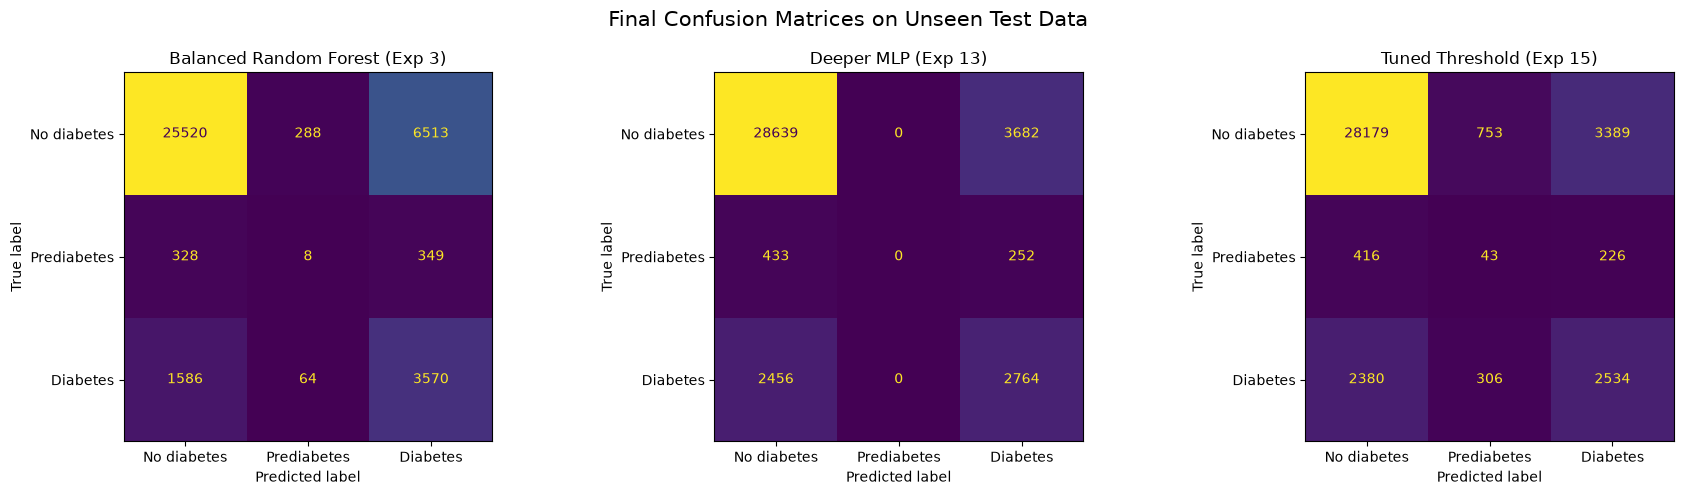

Test confusion matrices saved.


In [91]:
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

test_predictions = {
    "Balanced Random Forest (Exp 3)": np.argmax(rf_prob, axis=1),
    "Deeper MLP (Exp 13)": mlp_pred,
    "Tuned Threshold (Exp 15)": mlp_threshold_pred
}

labels = [0, 1, 2]
class_names = ["No diabetes", "Prediabetes", "Diabetes"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(
    axes, test_predictions.items()
):
    cm = confusion_matrix(
        y_test_final,
        predictions,
        labels=labels
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    ).plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle(
    "Final Confusion Matrices on Unseen Test Data",
    fontsize=15
)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "final_test_confusion_matrices.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Test confusion matrices saved.")

The confusion matrices reveal clear differences in how the models classify the three diabetes-related classes.

**Experiment 3  Balanced Random Forest:** The model correctly identified 3,570 diabetes cases but only 8 prediabetes cases. It frequently misclassified no-diabetes cases as diabetes, reducing its overall accuracy to 76.12%. Its diabetes recall was relatively strong at 68.39%, but prediabetes detection remained extremely weak.

**Experiment 13  Deeper MLP:** This model correctly classified 28,639 no-diabetes cases and 2,764 diabetes cases. However, it failed to predict any prediabetes cases, demonstrating that good performance on the majority class does not guarantee balanced classification.

**Experiment 15 Tuned Threshold:** Adjusting the prediabetes threshold allowed the model to identify 43 prediabetes cases, compared with zero in Experiment 13. However, it also incorrectly labelled 1,059 cases from the other classes as prediabetes. Consequently, prediabetes precision remained low at 3.90%, despite recall improving to 6.28%.

Threshold tuning improved prediabetes detection slightly, but all three approaches struggled with this minority class. These results reinforce the need to evaluate precision, recall, and macro F1 alongside accuracy.


## Bias Variance Analysis, Dataset Limitations, and Future Improvements

### 1. Bias Variance Analysis

The experiments highlight the challenge of developing a model that generalizes well while identifying all three diabetes-related classes. The unweighted MLP achieved 84.85% validation accuracy but failed to identify prediabetes, showing a strong tendency to favor the majority class. This reflects class-specific prediction bias, although it does not alone establish high bias in the formal bias–variance framework. Experiments 12 and 13 showed decreasing training loss while validation loss eventually plateaued, suggesting diminishing generalization improvements and possible mild overfitting in later epochs. Experiment 16 showed relatively stable training and validation loss, but prediabetes recall remained zero. On unseen test data, Experiment 13 achieved a macro F1-score of 0.4536, close to its validation score of 0.4551, suggesting consistent overall performance across the two splits. These findings show that stable generalization does not necessarily mean the model identifies every class adequately, which is important for a health-awareness application.

### 2. Dataset Limitations

The dataset is highly imbalanced: approximately 84.24% of the original records represent no diabetes, 1.83% prediabetes, and 13.93% diabetes. This imbalance makes prediabetes particularly difficult to identify. The data comes from the 2015 US Behavioral Risk Factor Surveillance System (BRFSS) and relies on self-reported health indicators, which may contain reporting errors and may not reflect laboratory-confirmed health status. Its age and US population also limit how confidently the findings can be generalized to current populations or other countries, including Rwanda. Furthermore, identical predictor patterns can have conflicting target labels, suggesting possible label ambiguity or differences not captured by the available features. Group-based splitting reduced the risk of identical predictor patterns appearing across training, validation, and test sets, but exact duplicate records were retained in the current experiments. A separate deduplication experiment will investigate their potential effect. Therefore, this dataset supports exploratory classification research, but the resulting models should not be treated as clinical diagnostic tools or assumed to estimate future diabetes risk.

### 3. Future Improvements

Future work should focus on improving prediabetes detection while controlling false-positive predictions. On the unseen test set, the MLP with the threshold selected in Experiment 15 achieved a macro F1-score of 0.4614, compared with 0.4536 for the original deeper MLP. However, prediabetes precision was only 3.90% and recall was 6.28%, meaning that the improvement remains insufficient for a reliable screening application. Further experiments could investigate carefully tuned class weights, probability calibration, and synthetic minority oversampling methods such as SMOTE or SMOTENC, applied only to training data and checked for realistic health-feature values. Group-aware cross-validation could provide more robust model comparisons, while deduplication sensitivity analysis could determine whether repeated records affect performance. Most importantly, future development would require external validation using more recent and representative data from the intended populations, followed by appropriate clinical evaluation before any real-world deployment.

Overall, the deeper MLP with focal loss showed reasonably consistent performance between validation and test data, while threshold tuning produced a modest improvement in macro F1. Nevertheless, weak prediabetes detection remains the main limitation. The results provide an initial investigation into classifying diabetes-related survey information, rather than evidence of a ready-to-use health-awareness application. With improved minority-class detection, representative data, and appropriate validation, this approach could be investigated further as a tool to encourage people to seek professional screening when needed.
